In [142]:

# GEO ALERTA OREAMUNO
# 01. Preparación del entorno

!pip -q install geopandas rasterio pyogrio requests



In [143]:

import geopandas as gpd
import requests

# Servicios geográficos
URL_CANTONES = (
    "https://services5.arcgis.com/4u1m1BBDkNDTVWsd/"
    "arcgis/rest/services/Cant%C3%B3n/FeatureServer/0/query"
)

URL_DISTRITOS = (
    "https://services5.arcgis.com/4u1m1BBDkNDTVWsd/"
    "arcgis/rest/services/Distritos_CR/FeatureServer/0/query"
)

def consultar_servicio(url):
    parametros = {
        "where": "1=1",
        "outFields": "*",
        "returnGeometry": "true",
        "outSR": "5367",
        "f": "geojson"
    }

    respuesta = requests.get(
        url, params=parametros, timeout=120
    )
    respuesta.raise_for_status()

    datos = respuesta.json()

    if "features" not in datos:
        raise ValueError(datos)

    return gpd.GeoDataFrame.from_features(
        datos["features"],
        crs="EPSG:5367"
    )

# Descargar capas nacionales
cantones = consultar_servicio(URL_CANTONES)
distritos = consultar_servicio(URL_DISTRITOS)

print("Cantones:", len(cantones))
print("Distritos:", len(distritos))

print("\nCampos de cantones:")
print(cantones.columns.tolist())

print("\nCampos de distritos:")
print(distritos.columns.tolist())

print("\nPrimeros registros distritales:")
display(distritos.drop(columns="geometry").head())


Cantones: 82
Distritos: 487

Campos de cantones:
['geometry', 'OBJECTID_12', 'cod_prov', 'nom_cant', 'nom_prov', 'poblacion', 'area_km2', 'perime_km', 'cod_canton', 'Shape__Area', 'Shape__Length']

Campos de distritos:
['geometry', 'OBJECTID_12', 'nom_prov', 'canton', 'poblacion', 'nom_distr', 'cod_distr', 'area_km2', 'perime_km', 'cod_canton', 'Shape__Area', 'Shape__Length']

Primeros registros distritales:


,OBJECTID_12,nom_prov,canton,poblacion,nom_distr,cod_distr,area_km2,perime_km,cod_canton,Shape__Area,Shape__Length
0,1,Puntarenas,CORREDORES,0,LA CUESTA,2,37.116084,29.463184,610,3.711608e+07,29463.184368
1,2,Puntarenas,CORREDORES,0,LAUREL,4,188.744547,90.497846,610,1.887445e+08,90497.845678
2,3,Puntarenas,CORREDORES,0,CANOAS,3,122.061299,63.571050,610,1.220613e+08,63571.049872
3,4,Puntarenas,GOLFITO,0,PUERTO JIMÉNEZ,2,719.490447,188.943980,607,7.194904e+08,188943.979924
4,5,Puntarenas,CORREDORES,0,CORREDOR,1,275.766919,123.712169,610,2.757669e+08,123712.169008


In [144]:

# Buscar Oreamuno en los atributos de ambas capas

for nombre, capa in [
    ("CANTONES", cantones),
    ("DISTRITOS", distritos)
]:
    print(f"\n--- {nombre} ---")

    columnas_texto = capa.select_dtypes(
        include=["object", "string"]
    ).columns

    for campo in columnas_texto:
        coincidencias = capa[
            capa[campo].astype(str).str.contains(
                "Oreamuno", case=False, na=False
            )
        ]

        if not coincidencias.empty:
            print(f"\nCampo: {campo}")
            display(
                coincidencias.drop(columns="geometry")
            )



--- CANTONES ---

Campo: nom_cant


,OBJECTID_12,cod_prov,nom_cant,nom_prov,poblacion,area_km2,perime_km,cod_canton,Shape__Area,Shape__Length
25,26,3,Oreamuno,Cartago,0,202.898728,101.851952,307,2.028987e+08,101851.951799



--- DISTRITOS ---

Campo: canton


,OBJECTID_12,nom_prov,canton,poblacion,nom_distr,cod_distr,area_km2,perime_km,cod_canton,Shape__Area,Shape__Length
108,109,Cartago,OREAMUNO,0,SAN RAFAEL,1,10.277107,15.810041,307,1.027711e+07,15810.041357
131,132,Cartago,OREAMUNO,0,CIPRESES,4,9.370066,16.005049,307,9.370066e+06,16005.048548
133,134,Cartago,OREAMUNO,0,COT,2,14.864792,23.741589,307,1.486479e+07,23741.588814
200,201,Cartago,OREAMUNO,0,POTRERO CERRADO,3,18.112408,26.779146,307,1.811241e+07,26779.146492
332,333,Cartago,OREAMUNO,0,SANTA ROSA,5,150.274355,80.542699,307,1.502744e+08,80542.698886


In [145]:
import os

# Definir el directorio del proyecto si no está definido
PROYECTO = "/content/GeoAlerta_Oreamuno"
os.makedirs(os.path.join(PROYECTO, "01_Datos_Originales"), exist_ok=True)

# Selección administrativa de Oreamuno
# Usando 'nom_cant' para cantones y 'canton' para distritos según los campos mostrados anteriormente
oreamuno = cantones[
    cantones["nom_cant"].str.upper() == "OREAMUNO"
].copy()

distritos_oreamuno = distritos[
    distritos["canton"].str.upper() == "OREAMUNO"
].copy()

# Sistema de coordenadas oficial de trabajo
oreamuno = oreamuno.to_crs("EPSG:5367")
distritos_oreamuno = distritos_oreamuno.to_crs("EPSG:5367")

# Verificar cantidad de registros
print("Polígonos cantonales:", len(oreamuno))
print("Polígonos distritales:", len(distritos_oreamuno))

# Verificar geometrías
print("Geometrías cantonales válidas:",
      oreamuno.geometry.is_valid.all())

print("Geometrías distritales válidas:",
      distritos_oreamuno.geometry.is_valid.all())

# Exportar
oreamuno.to_file(
    os.path.join(PROYECTO, "01_Datos_Originales",
                 "Oreamuno_Canton.gpkg"),
    driver="GPKG"
)

distritos_oreamuno.to_file(
    os.path.join(PROYECTO, "01_Datos_Originales",
                 "Oreamuno_Distritos.gpkg"),
    driver="GPKG"
)

print("\nCapas exportadas correctamente.")

Polígonos cantonales: 1
Polígonos distritales: 5
Geometrías cantonales válidas: True
Geometrías distritales válidas: True

Capas exportadas correctamente.


In [146]:

# Instalación de librerías
!pip install -q pysheds

# Configuración GDAL para lectura de COG remotos
import os
os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"

# Librerías generales
import math
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Procesamiento raster
import rasterio
from rasterio.merge import merge
from rasterio.plot import show
from rasterio.warp import (
    calculate_default_transform,
    reproject,
    Resampling,
    transform_bounds
)

# Geometrías y proyecciones
from shapely.geometry import box
from shapely.ops import unary_union
from pyproj import Transformer

# Procesamiento hidrológico
from pysheds.grid import Grid

print("Entorno preparado correctamente")
print("Rasterio:", rasterio.__version__)
print("GeoPandas:", gpd.__version__)


Entorno preparado correctamente
Rasterio: 1.5.2
GeoPandas: 1.2.0


In [147]:

# Nombre del proyecto
NOMBRE_AREA = "OREAMUNO"

# Sistema de referencia de trabajo
CRS_TRABAJO = "EPSG:5367"

# Recuperar los distritos y reproyectar
limite = distritos_oreamuno.to_crs(CRS_TRABAJO)

# Unificar las geometrías distritales
geometria_oreamuno = unary_union(limite.geometry)

# Crear margen exterior de 5 km
# Esto permite conservar zonas de aporte externas al cantón
area_descarga = geometria_oreamuno.buffer(5000)

# Obtener extensión proyectada
xmin, ymin, xmax, ymax = area_descarga.bounds

# Transformar extensión a coordenadas geográficas
LON_MIN, LAT_MIN, LON_MAX, LAT_MAX = transform_bounds(
    CRS_TRABAJO,
    "EPSG:4326",
    xmin, ymin, xmax, ymax,
    densify_pts=21
)

print("Área de estudio:", NOMBRE_AREA)
print("Margen exterior: 5 km")

print("\nExtensión geográfica:")
print(f"Latitud: {LAT_MIN:.6f} a {LAT_MAX:.6f}")
print(f"Longitud: {LON_MIN:.6f} a {LON_MAX:.6f}")


Área de estudio: OREAMUNO
Margen exterior: 5 km

Extensión geográfica:
Latitud: 9.802478 a 10.192706
Longitud: -83.993028 a -83.754542


In [148]:

def _url_tesela(lat, lon, glo=30):
    """Construye la URL de una tesela Copernicus."""

    res = "10" if glo == 30 else "30"

    ns = "N" if lat >= 0 else "S"
    ew = "E" if lon >= 0 else "W"

    nombre = (
        f"Copernicus_DSM_COG_{res}_"
        f"{ns}{abs(lat):02d}_00_"
        f"{ew}{abs(lon):03d}_00_DEM"
    )

    return (
        f"https://copernicus-dem-{glo}m.s3.amazonaws.com/"
        f"{nombre}/{nombre}.tif"
    )


def obtener_dem(lat_min, lon_min, lat_max, lon_max, glo=30):
    """
    Descarga y mosaica las teselas Copernicus.
    Devuelve matriz DEM, transformación y perfil.
    """

    teselas = [
        (la, lo)
        for la in range(math.floor(lat_min),
                        math.floor(lat_max) + 1)
        for lo in range(math.floor(lon_min),
                        math.floor(lon_max) + 1)
    ]

    abiertas = []

    try:
        for la, lo in teselas:

            url = _url_tesela(la, lo, glo)

            print(f"Abriendo tesela: {la}, {lo}")

            abiertas.append(rasterio.open(url))

        mosaico, transform = merge(
            abiertas,
            bounds=(lon_min, lat_min, lon_max, lat_max)
        )

        perfil = abiertas[0].profile.copy()

        perfil.update(
            driver="GTiff",
            count=1,
            height=mosaico.shape[1],
            width=mosaico.shape[2],
            transform=transform
        )

        print(f"\nCopernicus GLO-{glo}")
        print("Teselas utilizadas:", len(teselas))
        print(
            f"Dimensiones: {mosaico.shape[2]} x "
            f"{mosaico.shape[1]} celdas"
        )

        return mosaico[0], transform, perfil

    finally:
        for archivo in abiertas:
            archivo.close()


In [149]:

# Descargar Copernicus GLO-30

z, transform_dem, perfil = obtener_dem(
    LAT_MIN,
    LON_MIN,
    LAT_MAX,
    LON_MAX,
    glo=30
)

print("\nINSPECCIÓN DEL MODELO")

print("Dimensiones:", z.shape)
print("CRS:", perfil["crs"])
print("NoData:", perfil["nodata"])
print("Tipo de dato:", perfil["dtype"])

# Estadísticas de elevación
datos_validos = z[
    np.isfinite(z) &
    (z != perfil["nodata"])
]

print("Elevación mínima:", np.min(datos_validos), "m")
print("Elevación máxima:", np.max(datos_validos), "m")
print("Elevación media:", np.mean(datos_validos), "m")


Abriendo tesela: 9, -84
Abriendo tesela: 10, -84

Copernicus GLO-30
Teselas utilizadas: 2
Dimensiones: 859 x 1405 celdas

INSPECCIÓN DEL MODELO
Dimensiones: (1405, 859)
CRS: EPSG:4326
NoData: None
Tipo de dato: float32
Elevación mínima: 293.64328 m
Elevación máxima: 3431.7466 m
Elevación media: 1502.9335 m


In [150]:

# Ruta de almacenamiento
ruta_dem_original = os.path.join(
    PROYECTO,
    "01_Datos_Originales",
    "Oreamuno_Copernicus_GLO30.tif"
)

# Guardar GeoTIFF
with rasterio.open(
    ruta_dem_original,
    "w",
    **perfil
) as dst:

    dst.write(z, 1)

print("DEM guardado correctamente:")
print(ruta_dem_original)


DEM guardado correctamente:
/content/GeoAlerta_Oreamuno/01_Datos_Originales/Oreamuno_Copernicus_GLO30.tif


In [151]:

# Reproyección a CRTM05
ruta_dem_proyectado = os.path.join(
    PROYECTO,
    "02_Datos_Procesados",
    "Oreamuno_Copernicus_GLO30_CRTM05.tif"
)

# Asegurar que el directorio de salida existe
os.makedirs(os.path.dirname(ruta_dem_proyectado), exist_ok=True)

with rasterio.open(ruta_dem_original) as src:

    destino_crs = "EPSG:5367"

    transformacion, ancho, alto = (
        calculate_default_transform(
            src.crs,
            destino_crs,
            src.width,
            src.height,
            *src.bounds
        )
    )

    nodata = (
        src.nodata if src.nodata is not None else -9999.0
    )

    destino = np.full(
        (alto, ancho),
        nodata,
        dtype=np.float32
    )

    reproject(
        source=rasterio.band(src, 1),
        destination=destino,
        src_transform=src.transform,
        src_crs=src.crs,
        src_nodata=src.nodata,
        dst_transform=transformacion,
        dst_crs=destino_crs,
        dst_nodata=nodata,
        resampling=Resampling.bilinear
    )

    perfil_salida = src.profile.copy()

    perfil_salida.update(
        driver="GTiff",
        crs=destino_crs,
        transform=transformacion,
        width=ancho,
        height=alto,
        count=1,
        dtype="float32",
        nodata=nodata,
        compress="deflate"
    )

with rasterio.open(
    ruta_dem_proyectado,
    "w",
    **perfil_salida
) as dst:

    dst.write(destino, 1)

print("Reproyección completada.")
print("CRS: EPSG:5367")
print("Tamaño de celda:",
      transformacion.a, "metros")
print("Archivo:", ruta_dem_proyectado)


Reproyección completada.
CRS: EPSG:5367
Tamaño de celda: 30.64849007980545 metros
Archivo: /content/GeoAlerta_Oreamuno/02_Datos_Procesados/Oreamuno_Copernicus_GLO30_CRTM05.tif


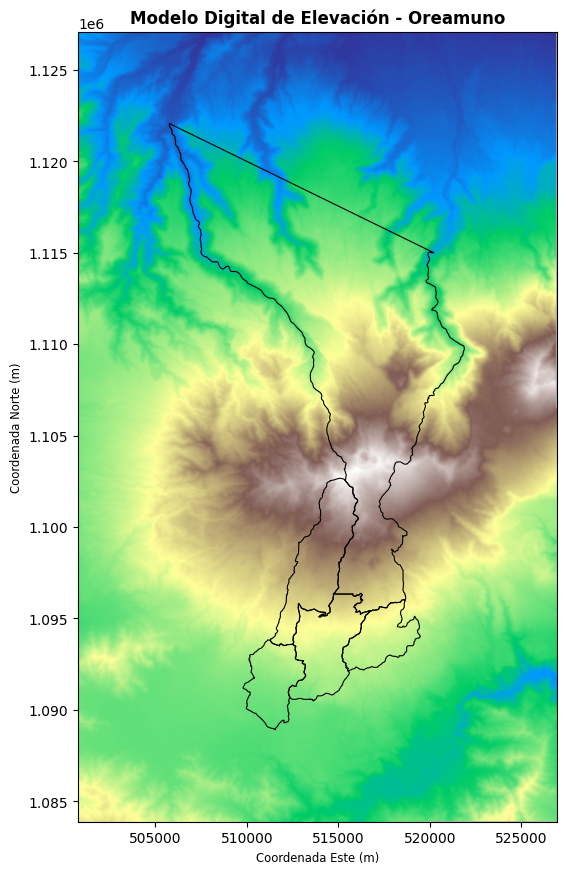

In [152]:

# Visualizar el modelo reproyectado

with rasterio.open(ruta_dem_proyectado) as src:

    fig, ax = plt.subplots(figsize=(11, 9))

    show(
        src,
        ax=ax,
        cmap="terrain",
        title="Modelo Digital de Elevación - Oreamuno"
    )

    # Superponer límites distritales
    distritos_oreamuno.to_crs(
        "EPSG:5367"
    ).boundary.plot(
        ax=ax,
        color="black",
        linewidth=0.8
    )

    ax.set_xlabel("Coordenada Este (m)")
    ax.set_ylabel("Coordenada Norte (m)")

    plt.tight_layout()
    plt.show()


In [153]:

import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource

# Se define la ruta del DEM reproyectado
ruta_dem_proyectado = os.path.join(
    PROYECTO,
    "02_Datos_Procesados",
    "Oreamuno_Copernicus_GLO30_CRTM05.tif"
)

with rasterio.open(ruta_dem_proyectado) as src:
    elevacion = src.read(1).astype("float32")
    perfil_dem = src.profile.copy()
    transformacion = src.transform
    nodata = src.nodata

    resolucion_x = abs(transformacion.a)
    resolucion_y = abs(transformacion.e)

    print("CRS:", src.crs)
    print("Dimensiones:", src.width, "x", src.height)
    print("Resolución X:", resolucion_x, "m")
    print("Resolución Y:", resolucion_y, "m")
    print("NoData:", nodata)

# Se identifica la información válida del DEM
mascara_valida = np.isfinite(elevacion)

if nodata is not None:
    mascara_valida &= elevacion != nodata

print("Píxeles válidos:", np.sum(mascara_valida))
print("Elevación mínima:", np.nanmin(np.where(mascara_valida, elevacion, np.nan)))
print("Elevación máxima:", np.nanmax(np.where(mascara_valida, elevacion, np.nan)))


CRS: EPSG:5367
Dimensiones: 854 x 1409
Resolución X: 30.64849007980545 m
Resolución Y: 30.64849007980545 m
NoData: -9999.0
Píxeles válidos: 1202378
Elevación mínima: 295.8774
Elevación máxima: 3431.473


In [154]:

# Se reemplazan los valores NoData por NaN
elevacion_limpia = np.where(
    mascara_valida,
    elevacion,
    np.nan
)

# Se calculan los gradientes del terreno
gradiente_y, gradiente_x = np.gradient(
    elevacion_limpia,
    resolucion_y,
    resolucion_x
)

# Se calcula la pendiente en grados
pendiente = np.degrees(
    np.arctan(
        np.sqrt(gradiente_x**2 + gradiente_y**2)
    )
).astype("float32")

# Se define el valor NoData de salida
nodata_salida = -9999.0

pendiente[~np.isfinite(pendiente)] = nodata_salida

# Se guarda el raster de pendientes
ruta_pendiente = os.path.join(
    PROYECTO,
    "02_Datos_Procesados",
    "Oreamuno_Pendiente_grados.tif"
)

perfil_salida = perfil_dem.copy()
perfil_salida.update(
    dtype="float32",
    count=1,
    nodata=nodata_salida,
    compress="deflate"
)

with rasterio.open(ruta_pendiente, "w", **perfil_salida) as dst:
    dst.write(pendiente, 1)

print("Pendiente generada correctamente.")
print(ruta_pendiente)


Pendiente generada correctamente.
/content/GeoAlerta_Oreamuno/02_Datos_Procesados/Oreamuno_Pendiente_grados.tif


In [155]:

# Se genera el sombreado del relieve
fuente_luz = LightSource(
    azdeg=315,
    altdeg=45
)

hillshade = fuente_luz.hillshade(
    elevacion_limpia,
    vert_exag=1,
    dx=resolucion_x,
    dy=resolucion_y
).astype("float32")

hillshade[~mascara_valida] = nodata_salida

# Se guarda el hillshade
ruta_hillshade = os.path.join(
    PROYECTO,
    "02_Datos_Procesados",
    "Oreamuno_Hillshade.tif"
)

with rasterio.open(ruta_hillshade, "w", **perfil_salida) as dst:
    dst.write(hillshade, 1)

print("Hillshade generado correctamente.")
print(ruta_hillshade)


Hillshade generado correctamente.
/content/GeoAlerta_Oreamuno/02_Datos_Procesados/Oreamuno_Hillshade.tif


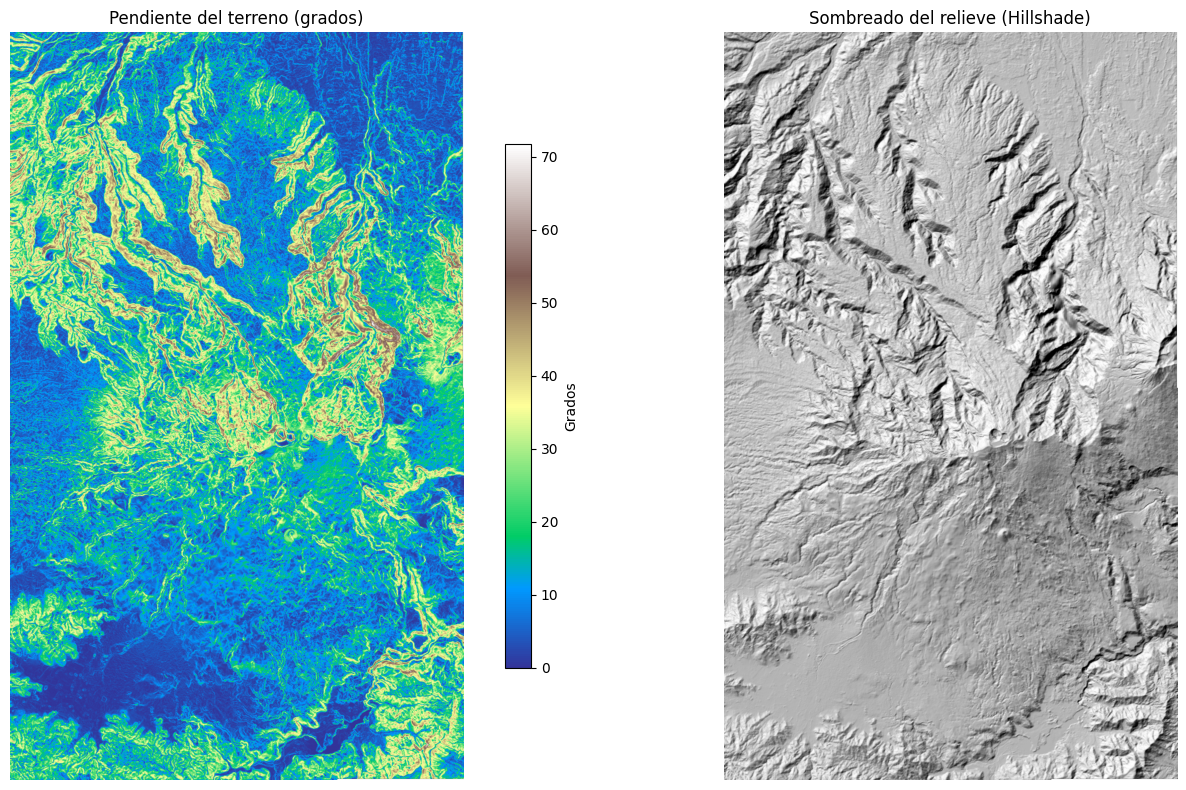

In [156]:

fig, ejes = plt.subplots(1, 2, figsize=(16, 8))

# Mapa de pendientes
pendiente_visual = np.where(
    pendiente == nodata_salida,
    np.nan,
    pendiente
)

imagen1 = ejes[0].imshow(
    pendiente_visual,
    cmap="terrain"
)
ejes[0].set_title("Pendiente del terreno (grados)")
plt.colorbar(imagen1, ax=ejes[0], shrink=0.7, label="Grados")

# Mapa de sombreado
hillshade_visual = np.where(
    hillshade == nodata_salida,
    np.nan,
    hillshade
)

ejes[1].imshow(
    hillshade_visual,
    cmap="gray"
)
ejes[1].set_title("Sombreado del relieve (Hillshade)")

for ax in ejes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [157]:

from pysheds.grid import Grid
import numpy as np
import rasterio
import os

# Se carga el DEM reproyectado
grid = Grid.from_raster(ruta_dem_proyectado)
dem = grid.read_raster(ruta_dem_proyectado)

print("DEM cargado correctamente en PySheds.")
print("Dimensiones:", dem.shape)


DEM cargado correctamente en PySheds.
Dimensiones: (1409, 854)


In [158]:

# Se rellenan las depresiones cerradas
dem_sin_pozos = grid.fill_pits(dem)

# Se rellenan las depresiones del terreno
dem_relleno = grid.fill_depressions(dem_sin_pozos)

# Se resuelven las superficies planas
dem_acondicionado = grid.resolve_flats(dem_relleno)

print("Acondicionamiento hidrológico completado.")


Acondicionamiento hidrológico completado.


In [159]:
ruta_dem_acondicionado = os.path.join(
    PROYECTO,
    "03_Modelos_Hidrologicos",
    "Oreamuno_DEM_Acondicionado.tif"
)

# Asegurar que el directorio de destino existe
os.makedirs(os.path.dirname(ruta_dem_acondicionado), exist_ok=True)

# Se conserva el perfil espacial del DEM original
with rasterio.open(ruta_dem_proyectado) as src:
    perfil_hidrologico = src.profile.copy()

perfil_hidrologico.update(
    dtype="float32",
    count=1,
    compress="deflate"
)

with rasterio.open(
    ruta_dem_acondicionado,
    "w",
    **perfil_hidrologico
) as dst:
    dst.write(np.asarray(dem_acondicionado, dtype="float32"), 1)

print("DEM acondicionado guardado:")
print(ruta_dem_acondicionado)

DEM acondicionado guardado:
/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_DEM_Acondicionado.tif


In [160]:

# Se define la codificación D8
dirmap = (64, 128, 1, 2, 4, 8, 16, 32)

# Se calcula la dirección de flujo
direccion_flujo = grid.flowdir(
    dem_acondicionado,
    dirmap=dirmap
)

print("Dirección de flujo calculada correctamente.")


Dirección de flujo calculada correctamente.


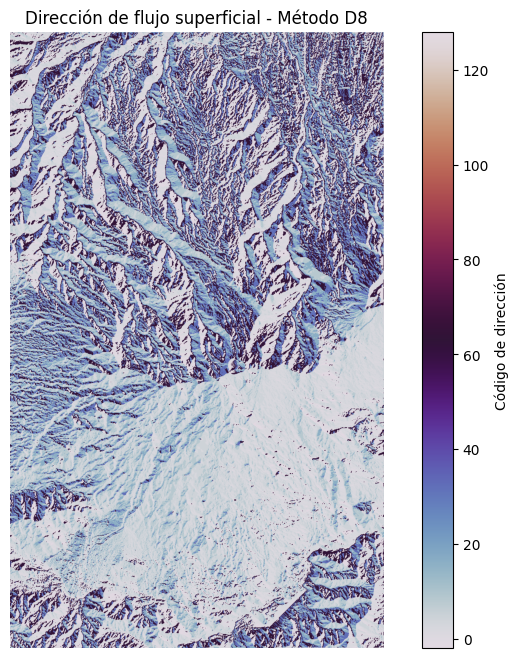

Resultado guardado: /content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Direccion_Flujo_D8.tif


In [161]:

ruta_direccion = os.path.join(
    PROYECTO,
    "03_Modelos_Hidrologicos",
    "Oreamuno_Direccion_Flujo_D8.tif"
)

perfil_direccion = perfil_hidrologico.copy()
perfil_direccion.update(
    dtype="int16",
    nodata=-9999
)

# Se guarda la dirección de flujo
with rasterio.open(ruta_direccion, "w", **perfil_direccion) as dst:
    dst.write(
        np.asarray(direccion_flujo, dtype="int16"),
        1
    )

# Se visualiza el resultado
plt.figure(figsize=(10, 8))
plt.imshow(direccion_flujo, cmap="twilight")
plt.title("Dirección de flujo superficial - Método D8")
plt.axis("off")
plt.colorbar(label="Código de dirección")
plt.show()

print("Resultado guardado:", ruta_direccion)


In [162]:
# Acumulación de flujo

# Solución temporal al error de compatibilidad de NumPy con PySheds
if not hasattr(np, "in1d"):
    np.in1d = np.isin

# Se calcula la acumulación de flujo utilizando D8
acumulacion_flujo = grid.accumulation(
    direccion_flujo,
    dirmap=dirmap
)

print("Acumulación de flujo calculada.")
print("Valor mínimo:", np.nanmin(acumulacion_flujo))
print("Valor máximo:", np.nanmax(acumulacion_flujo))

Acumulación de flujo calculada.
Valor mínimo: 0.0
Valor máximo: 386403.0


In [163]:

ruta_acumulacion = os.path.join(
    PROYECTO,
    "03_Modelos_Hidrologicos",
    "Oreamuno_Acumulacion_Flujo.tif"
)

perfil_acumulacion = perfil_hidrologico.copy()
perfil_acumulacion.update(
    dtype="float32",
    nodata=-9999,
    compress="deflate"
)

# Se guarda el raster de acumulación
with rasterio.open(
    ruta_acumulacion,
    "w",
    **perfil_acumulacion
) as dst:
    dst.write(
        np.asarray(acumulacion_flujo, dtype="float32"),
        1
    )

print("Archivo guardado:", ruta_acumulacion)


Archivo guardado: /content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Acumulacion_Flujo.tif


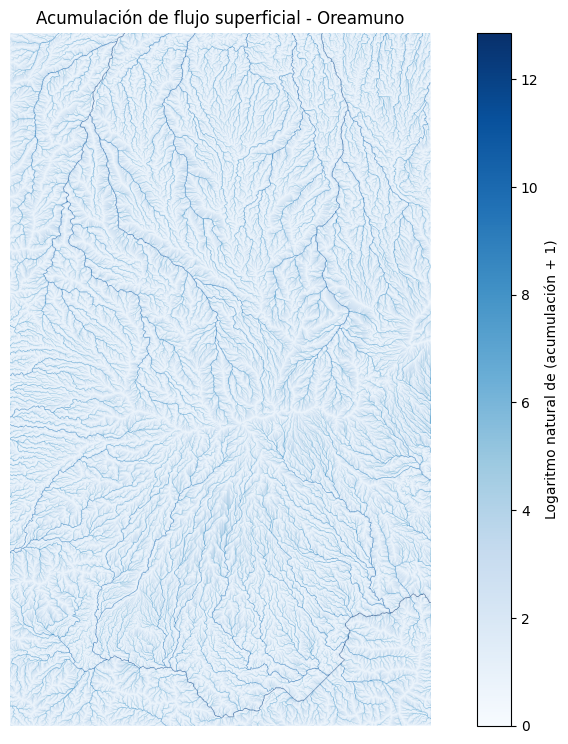

In [164]:

# Se transforma la acumulación mediante logaritmo
acumulacion_visual = np.log1p(
    np.maximum(
        np.asarray(acumulacion_flujo, dtype="float32"),
        0
    )
)

plt.figure(figsize=(12, 9))

plt.imshow(
    acumulacion_visual,
    cmap="Blues"
)

plt.title("Acumulación de flujo superficial - Oreamuno")
plt.colorbar(
    label="Logaritmo natural de (acumulación + 1)"
)

plt.axis("off")
plt.show()


In [165]:

# Se convierte la acumulación en un arreglo numérico
acum = np.asarray(acumulacion_flujo, dtype="float64")

# Se seleccionan los valores válidos
acum_valida = acum[np.isfinite(acum) & (acum >= 0)]

# Se calculan estadísticas descriptivas
print("ESTADÍSTICAS DE ACUMULACIÓN DE FLUJO")
print("-----------------------------------")
print("Número de celdas:", len(acum_valida))
print("Mínimo:", np.min(acum_valida))
print("Máximo:", np.max(acum_valida))
print("Media:", np.mean(acum_valida))
print("Mediana:", np.median(acum_valida))

# Se calculan percentiles
percentiles = [50, 75, 90, 95, 97, 99, 99.5, 99.9]

print("\nPERCENTILES")
for p in percentiles:
    print(f"P{p}: {np.percentile(acum_valida, p):,.2f}")

# Se calcula el área aproximada por celda
area_celda = resolucion_x * resolucion_y

print("\nÁREA DE CONTRIBUCIÓN")
print("Área por celda:", area_celda, "m²")


ESTADÍSTICAS DE ACUMULACIÓN DE FLUJO
-----------------------------------
Número de celdas: 1203286
Mínimo: 0.0
Máximo: 386403.0
Media: 448.0554032873315
Mediana: 3.0

PERCENTILES
P50: 3.00
P75: 8.00
P90: 40.00
P95: 202.00
P97: 675.00
P99: 5,177.00
P99.5: 15,217.60
P99.9: 104,277.01

ÁREA DE CONTRIBUCIÓN
Área por celda: 939.329944171933 m²


In [166]:

# Se definen umbrales preliminares de acumulación
umbrales = [100, 250, 500, 1000, 2500, 5000, 10000]

print("COMPARACIÓN DE UMBRALES")
print("-----------------------------------")

for umbral in umbrales:

    celdas_cauce = np.sum(acum_valida >= umbral)

    area_km2 = (
        celdas_cauce * area_celda
    ) / 1_000_000

    print(
        f"Umbral: {umbral:>6} celdas | "
        f"Celdas: {celdas_cauce:>8,} | "
        f"Área contribuyente mínima: "
        f"{umbral * area_celda / 1_000_000:.4f} km² | "
        f"Área de celdas seleccionadas: {area_km2:.4f} km²"
    )


COMPARACIÓN DE UMBRALES
-----------------------------------
Umbral:    100 celdas | Celdas:   81,658 | Área contribuyente mínima: 0.0939 km² | Área de celdas seleccionadas: 76.7038 km²
Umbral:    250 celdas | Celdas:   55,261 | Área contribuyente mínima: 0.2348 km² | Área de celdas seleccionadas: 51.9083 km²
Umbral:    500 celdas | Celdas:   41,088 | Área contribuyente mínima: 0.4697 km² | Área de celdas seleccionadas: 38.5952 km²
Umbral:   1000 celdas | Celdas:   30,010 | Área contribuyente mínima: 0.9393 km² | Área de celdas seleccionadas: 28.1893 km²
Umbral:   2500 celdas | Celdas:   18,251 | Área contribuyente mínima: 2.3483 km² | Área de celdas seleccionadas: 17.1437 km²
Umbral:   5000 celdas | Celdas:   12,328 | Área contribuyente mínima: 4.6966 km² | Área de celdas seleccionadas: 11.5801 km²
Umbral:  10000 celdas | Celdas:    7,577 | Área contribuyente mínima: 9.3933 km² | Área de celdas seleccionadas: 7.1173 km²


In [167]:

# Se comparan tres umbrales de acumulación
umbrales_evaluacion = [250, 500, 1000]

print("EVALUACIÓN DE REDES DE DRENAJE")
print("=" * 65)

for umbral in umbrales_evaluacion:

    # Se identifican las celdas que superan el umbral
    mascara_cauce = acum >= umbral

    # Se contabilizan las celdas seleccionadas
    numero_celdas = np.sum(mascara_cauce)

    # Se estima la longitud de la red
    longitud_km = (
        numero_celdas * np.sqrt(area_celda)
    ) / 1000

    # Se calcula la densidad aproximada
    print(f"\nUmbral: {umbral} celdas")
    print(f"Celdas identificadas: {numero_celdas:,}")
    print(f"Longitud aproximada: {longitud_km:.2f} km")
    print(
        f"Área contribuyente mínima: "
        f"{umbral * area_celda / 1_000_000:.3f} km²"
    )


EVALUACIÓN DE REDES DE DRENAJE

Umbral: 250 celdas
Celdas identificadas: 55,261
Longitud aproximada: 1693.67 km
Área contribuyente mínima: 0.235 km²

Umbral: 500 celdas
Celdas identificadas: 41,088
Longitud aproximada: 1259.29 km
Área contribuyente mínima: 0.470 km²

Umbral: 1000 celdas
Celdas identificadas: 30,010
Longitud aproximada: 919.76 km
Área contribuyente mínima: 0.939 km²


In [168]:
print("DIAGNÓSTICO ESPACIAL")
print("------------------------------")

print("CRS del raster:", grid.crs)
print("Extensión del grid:", grid.extent)
print("Transformación:", grid.affine)

# Se inspecciona una geometría de la extracción anterior si existe la variable red_500
if 'red_500' in globals() and len(red_500) > 0:
    print("\nPrimera geometría:")
    print(red_500.geometry.iloc[0])

    print("\nExtensión de la red:")
    print(red_500.total_bounds)
elif 'redes_drenaje' in globals() and 500 in redes_drenaje:
    print("\nPrimera geometría:")
    print(redes_drenaje[500].geometry.iloc[0])

    print("\nExtensión de la red:")
    print(redes_drenaje[500].total_bounds)
else:
    print("\n[Info] La red de drenaje aún no ha sido extraída o la variable no está disponible.")

DIAGNÓSTICO ESPACIAL
------------------------------
CRS del raster: PROJCS["CR05 / CRTM05",GEOGCS["CR05",DATUM["Costa_Rica_2005",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","1065"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","5365"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-84],PARAMETER["scale_factor",0.9999],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Northing",NORTH],AXIS["Easting",EAST],AUTHORITY["EPSG","5367"]]
Extensión del grid: (500763.9116673815, 526937.7221955353, 1083883.3803346138, 1127067.1028570598)
Transformación: | 30.65, 0.00, 500763.91|
| 0.00,-30.65, 1127067.10|
| 0.00, 0.00, 1.00|

Primera geometría:
LINESTRING (507629.173445 1126546.078526, 507629.173445 1126576.727016, 507629.173445 1126607.375506, 507629.173445 1126638.02399

In [169]:

# Se establece el umbral de acumulación
umbral = 500

# Se genera una máscara booleana
mascara_cauce = acumulacion_flujo > umbral

print("Celdas que superan el umbral:", np.sum(mascara_cauce))

# Se extrae la red de drenaje
red_geojson_500 = grid.extract_river_network(
    direccion_flujo,
    mascara_cauce,
    dirmap=dirmap
)

# Se convierten las geometrías a GeoDataFrame
red_500 = gpd.GeoDataFrame.from_features(
    red_geojson_500["features"],
    crs=grid.crs
)

# Se calculan estadísticas geométricas
print("\nRESULTADOS DE LA EXTRACCIÓN")
print("------------------------------")
print("Segmentos:", len(red_500))
print("Longitud total:", round(red_500.length.sum() / 1000, 2), "km")
print("Extensión:", red_500.total_bounds)
print("CRS:", red_500.crs)


Celdas que superan el umbral: 41062

RESULTADOS DE LA EXTRACCIÓN
------------------------------
Segmentos: 1143
Longitud total: 1474.89 km
Extensión: [ 500763.911667 1083914.028825  526907.073705 1127067.102857]
CRS: PROJCS["CR05 / CRTM05",GEOGCS["CR05",DATUM["Costa_Rica_2005",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","1065"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","5365"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-84],PARAMETER["scale_factor",0.9999],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Northing",NORTH],AXIS["Easting",EAST],AUTHORITY["EPSG","5367"]]


In [170]:

umbrales_evaluacion = [250, 500, 1000]

redes_drenaje = {}

for umbral in umbrales_evaluacion:

    # Se genera la máscara de acumulación
    mascara_cauce = acumulacion_flujo > umbral

    # Se extrae la red de drenaje
    red_geojson = grid.extract_river_network(
        direccion_flujo,
        mascara_cauce,
        dirmap=dirmap
    )

    # Se convierte a GeoDataFrame
    red = gpd.GeoDataFrame.from_features(
        red_geojson["features"],
        crs=grid.crs
    )

    redes_drenaje[umbral] = red

    print(f"\nUMBRAL: {umbral}")
    print("Segmentos:", len(red))
    print(
        "Longitud:",
        round(red.length.sum() / 1000, 2),
        "km"
    )



UMBRAL: 250
Segmentos: 2259
Longitud: 1980.08 km

UMBRAL: 500
Segmentos: 1143
Longitud: 1474.89 km

UMBRAL: 1000
Segmentos: 612
Longitud: 1077.82 km


In [171]:

# Se preparan los límites cantonales
limite_oreamuno = distritos_oreamuno.to_crs("EPSG:5367")

redes_cantonales = {}

for umbral, red in redes_drenaje.items():

    # Se recorta la red al límite de Oreamuno
    red_recortada = gpd.clip(
        red,
        limite_oreamuno
    )

    redes_cantonales[umbral] = red_recortada

    print(f"\nUMBRAL: {umbral}")
    print("Segmentos dentro del cantón:", len(red_recortada))
    print(
        "Longitud dentro del cantón:",
        round(red_recortada.length.sum() / 1000, 2),
        "km"
    )



UMBRAL: 250
Segmentos dentro del cantón: 442
Longitud dentro del cantón: 345.26 km

UMBRAL: 500
Segmentos dentro del cantón: 218
Longitud dentro del cantón: 250.09 km

UMBRAL: 1000
Segmentos dentro del cantón: 112
Longitud dentro del cantón: 175.66 km


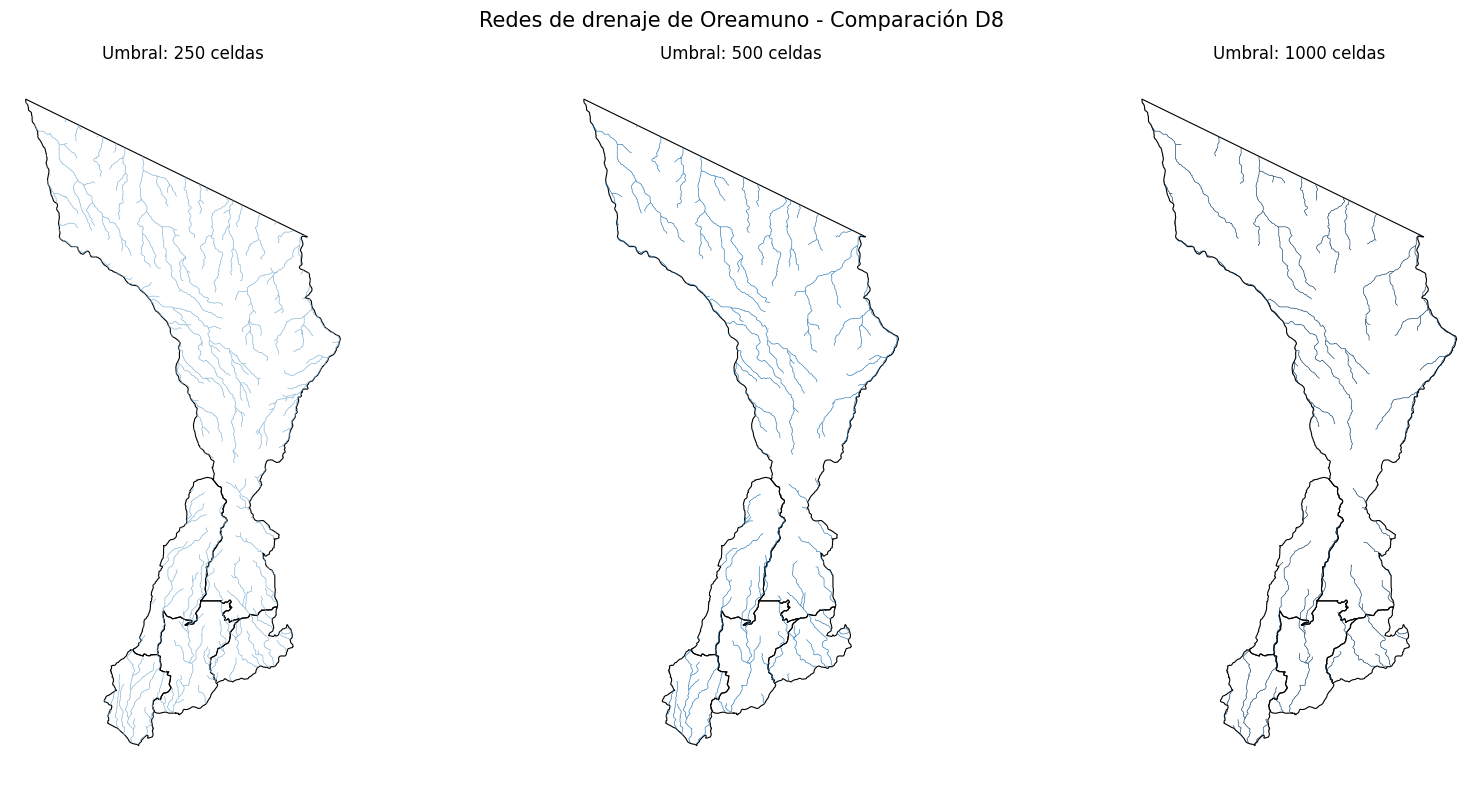

In [172]:

fig, ejes = plt.subplots(1, 3, figsize=(18, 8))

colores = ["#80b1d3", "#2878b5", "#083b66"]

for ax, umbral, color in zip(
    ejes,
    umbrales_evaluacion,
    colores
):

    limite_oreamuno.boundary.plot(
        ax=ax,
        color="black",
        linewidth=0.8
    )

    redes_cantonales[umbral].plot(
        ax=ax,
        color=color,
        linewidth=0.45
    )

    ax.set_title(f"Umbral: {umbral} celdas")
    ax.set_axis_off()

plt.suptitle(
    "Redes de drenaje de Oreamuno - Comparación D8",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [173]:

for umbral, red in redes_drenaje.items():

    ruta_completa = os.path.join(
        PROYECTO,
        "03_Modelos_Hidrologicos",
        f"Oreamuno_Red_Drenaje_{umbral}_Completa.gpkg"
    )

    ruta_cantonal = os.path.join(
        PROYECTO,
        "03_Modelos_Hidrologicos",
        f"Oreamuno_Red_Drenaje_{umbral}_Cantonal.gpkg"
    )

    red.to_file(ruta_completa, driver="GPKG")

    redes_cantonales[umbral].to_file(
        ruta_cantonal,
        driver="GPKG"
    )

print("Las seis capas de drenaje fueron guardadas.")


Las seis capas de drenaje fueron guardadas.


In [174]:
# Densidad de drenaje


from shapely.ops import unary_union

# Se calcula el área total del cantón
geometria_canton = unary_union(
    limite_oreamuno.geometry
)

area_canton_km2 = geometria_canton.area / 1_000_000

print("ÁREA DE OREAMUNO")
print("------------------------------")
print(f"Área cantonal: {area_canton_km2:.2f} km²")

# Se calcula la densidad para cada umbral
print("\nDENSIDAD DE DRENAJE")
print("------------------------------")

for umbral, red in redes_cantonales.items():

    longitud_km = red.length.sum() / 1000

    densidad = longitud_km / area_canton_km2

    print(f"\nUmbral: {umbral} celdas")
    print(f"Longitud: {longitud_km:.2f} km")
    print(f"Densidad: {densidad:.3f} km/km²")


ÁREA DE OREAMUNO
------------------------------
Área cantonal: 202.90 km²

DENSIDAD DE DRENAJE
------------------------------

Umbral: 250 celdas
Longitud: 345.26 km
Densidad: 1.702 km/km²

Umbral: 500 celdas
Longitud: 250.09 km
Densidad: 1.233 km/km²

Umbral: 1000 celdas
Longitud: 175.66 km
Densidad: 0.866 km/km²


In [175]:
import geopandas as gpd
from shapely.ops import unary_union, nearest_points

# Red completa de drenaje con umbral de 500
red_completa = redes_drenaje[500].copy()

# Límite cantonal unificado
limite = unary_union(limite_oreamuno.geometry)

# Distancia máxima respecto al límite (metros)
distancia_maxima = 150

candidatos = []

for geom in red_completa.geometry:
    if geom is None or geom.is_empty:
        continue

    distancia = geom.distance(limite)

    if distancia <= distancia_maxima:
        punto_red = nearest_points(geom, limite)[0]

        candidatos.append({
            "Dist_Limite_m": distancia,
            "geometry": punto_red
        })

# Se ordenan por proximidad al límite
candidatos = sorted(
    candidatos,
    key=lambda x: x["Dist_Limite_m"]
)

# Se eliminan puntos demasiado próximos entre sí
puntos_finales = []

for candidato in candidatos:
    punto = candidato["geometry"]

    if all(
        punto.distance(p["geometry"]) >= 150
        for p in puntos_finales
    ):
        puntos_finales.append(candidato)

# Crear capa geográfica
salidas_aproximadas = gpd.GeoDataFrame(
    [
        {
            "ID_Salida": i + 1,
            "Dist_Limite_m": round(p["Dist_Limite_m"], 2),
            "geometry": p["geometry"]
        }
        for i, p in enumerate(puntos_finales)
    ],
    crs="EPSG:5367"
)

print("PUNTOS DE SALIDA APROXIMADOS")
print("--------------------------------")
print(f"Candidatos encontrados: {len(candidatos)}")
print(f"Puntos seleccionados: {len(salidas_aproximadas)}")

if len(salidas_aproximadas) > 0:
    print(
        "Distancia máxima al límite:",
        round(salidas_aproximadas["Dist_Limite_m"].max(), 2),
        "metros"
    )

    # Corregido de carpeta_base a PROYECTO
    ruta = (
        f"{PROYECTO}/03_Modelos_Hidrologicos/"
        "Oreamuno_Salidas_Aproximadas.gpkg"
    )

    salidas_aproximadas.to_file(ruta, driver="GPKG")
    print("\nArchivo guardado:", ruta)

PUNTOS DE SALIDA APROXIMADOS
--------------------------------
Candidatos encontrados: 242
Puntos seleccionados: 209
Distancia máxima al límite: 133.04 metros

Archivo guardado: /content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Salidas_Aproximadas.gpkg


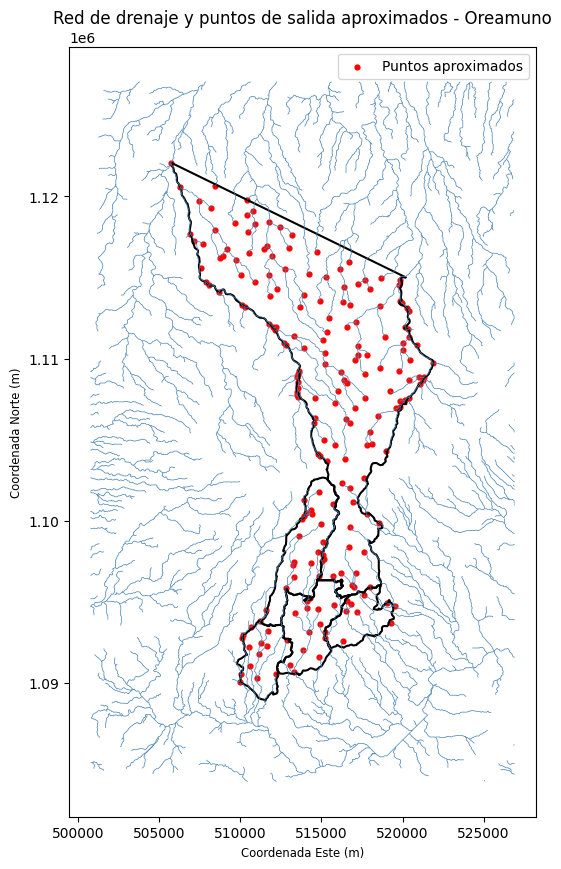

In [176]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

# Límite de Oreamuno
limite_oreamuno.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5
)

# Red de drenaje
red_completa.plot(
    ax=ax,
    color="steelblue",
    linewidth=0.5
)

# Puntos aproximados
salidas_aproximadas.plot(
    ax=ax,
    color="red",
    markersize=12,
    label="Puntos aproximados"
)

ax.set_title(
    "Red de drenaje y puntos de salida aproximados - Oreamuno"
)
ax.set_xlabel("Coordenada Este (m)")
ax.set_ylabel("Coordenada Norte (m)")
ax.legend()
ax.set_aspect("equal")

plt.show()

In [177]:
import geopandas as gpd
import rasterio
import numpy as np

# Raster de acumulación de flujo - Se corrige 'carpeta_base' por 'PROYECTO'
ruta_acc = (
    f"{PROYECTO}/03_Modelos_Hidrologicos/"
    "Oreamuno_Acumulacion_Flujo.tif"
)

# Se obtiene la acumulación correspondiente a cada punto
acumulaciones = []

with rasterio.open(ruta_acc) as src:

    for punto in salidas_aproximadas.geometry:
        fila, columna = src.index(punto.x, punto.y)

        valor = src.read(
            1,
            window=((fila, fila + 1), (columna, columna + 1))
        )[0, 0]

        acumulaciones.append(float(valor))

salidas_aproximadas["Acum_Flujo"] = acumulaciones

# Se ordenan de mayor a menor acumulación
candidatos = salidas_aproximadas.sort_values(
    "Acum_Flujo",
    ascending=False
)

# Selección espacial de puntos principales
seleccionados = []
distancia_minima = 1000  # metros
max_puntos = 20

for _, candidato in candidatos.iterrows():

    punto = candidato.geometry

    if all(
        punto.distance(seleccionado.geometry) >= distancia_minima
        for seleccionado in seleccionados
    ):
        seleccionados.append(candidato)

    if len(seleccionados) >= max_puntos:
        break

# Crear capa final
puntos_principales = gpd.GeoDataFrame(
    seleccionados,
    geometry="geometry",
    crs="EPSG:5367"
).reset_index(drop=True)

puntos_principales["ID_Punto"] = (
    np.arange(1, len(puntos_principales) + 1)
)

print("PUNTOS PRINCIPALES SELECCIONADOS")
print("--------------------------------")
print("Total:", len(puntos_principales))
print(
    "Acumulación máxima:",
    puntos_principales["Acum_Flujo"].max()
)

# Guardar - Se corrige 'carpeta_base' por 'PROYECTO'
ruta_final = (
    f"{PROYECTO}/03_Modelos_Hidrologicos/"
    "Oreamuno_Puntos_Salida_Principales.gpkg"
)

puntos_principales.to_file(ruta_final, driver="GPKG")

print("\nArchivo guardado:", ruta_final)

PUNTOS PRINCIPALES SELECCIONADOS
--------------------------------
Total: 20
Acumulación máxima: 85592.0

Archivo guardado: /content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Puntos_Salida_Principales.gpkg


In [178]:
print(
    puntos_principales[
        ["ID_Punto", "Acum_Flujo", "Dist_Limite_m"]
    ].to_string(index=False)
)

 ID_Punto  Acum_Flujo  Dist_Limite_m
        1     85592.0            0.0
        2     65914.0            0.0
        3     63131.0            0.0
        4     55291.0            0.0
        5     51601.0            0.0
        6     47200.0            0.0
        7     45170.0            0.0
        8     31888.0            0.0
        9     23610.0            0.0
       10     20366.0            0.0
       11     17029.0            0.0
       12     15700.0            0.0
       13     10802.0            0.0
       14     10563.0            0.0
       15      9201.0            0.0
       16      7105.0            0.0
       17      6586.0            0.0
       18      6557.0            0.0
       19      5640.0            0.0
       20      4870.0            0.0


In [179]:
import numpy as np
import rasterio

# Se selecciona el primer punto
punto = puntos_principales.iloc[0].geometry

# Se ejecuta la delimitación de la cuenca
cuenca_prueba = grid.catchment(
    x=punto.x,
    y=punto.y,
    fdir=direccion_flujo,
    xytype="coordinate",
    dirmap=dirmap
)

# Se calcula el área contribuyente
mascara = np.asarray(cuenca_prueba).astype(bool)

with rasterio.open(ruta_dem_proyectado) as src:
    area_pixel = abs(src.res[0] * src.res[1])

    cantidad_celdas = np.sum(mascara)
    area_km2 = cantidad_celdas * area_pixel / 1_000_000

print("RESULTADO DE LA DELIMITACIÓN")
print("--------------------------------")
print("Punto utilizado: 1")
print("Acumulación de flujo:", puntos_principales.iloc[0]["Acum_Flujo"])
print("Celdas delimitadas:", cantidad_celdas)
print(f"Área contribuyente: {area_km2:.2f} km²")

RESULTADO DE LA DELIMITACIÓN
--------------------------------
Punto utilizado: 1
Acumulación de flujo: 85592.0
Celdas delimitadas: 85592
Área contribuyente: 80.40 km²


In [180]:
import geopandas as gpd
import numpy as np
import rasterio
from rasterio.features import shapes
from shapely.geometry import shape
from shapely.ops import unary_union

resultados = []
poligonos = []

with rasterio.open(ruta_dem_proyectado) as src:

    transformacion = src.transform
    area_pixel = abs(src.res[0] * src.res[1])

    for _, punto_registro in puntos_principales.iterrows():

        punto = punto_registro.geometry

        # Delimitación del área de aporte
        cuenca = grid.catchment(
            x=punto.x,
            y=punto.y,
            fdir=direccion_flujo,
            xytype="coordinate",
            dirmap=dirmap
        )

        mascara = np.asarray(cuenca).astype(bool)

        # Cálculo del área
        cantidad = int(mascara.sum())
        area = cantidad * area_pixel / 1_000_000

        # Conversión a polígonos
        geometria = [
            shape(geom)
            for geom, valor in shapes(
                mascara.astype("uint8"),
                mask=mascara,
                transform=transformacion
            )
            if valor == 1
        ]

        if geometria:
            poligono = unary_union(geometria)

            poligonos.append({
                "ID_Punto": int(punto_registro["ID_Punto"]),
                "Acum_Flujo": float(punto_registro["Acum_Flujo"]),
                "Celdas": cantidad,
                "Area_km2": round(area, 2),
                "geometry": poligono
            })

        resultados.append({
            "ID_Punto": int(punto_registro["ID_Punto"]),
            "Acum_Flujo": float(punto_registro["Acum_Flujo"]),
            "Celdas": cantidad,
            "Area_km2": round(area, 2)
        })

# Crear capas
areas_aporte = gpd.GeoDataFrame(
    poligonos,
    geometry="geometry",
    crs="EPSG:5367"
)

tabla_aportes = gpd.pd.DataFrame(resultados)

# Exportar - Se corrige 'carpeta_base' por la variable definida 'PROYECTO'
ruta_areas = (
    f"{PROYECTO}/03_Modelos_Hidrologicos/"
    "Oreamuno_Areas_Aporte_Preliminares.gpkg"
)

areas_aporte.to_file(ruta_areas, driver="GPKG")

# Mostrar resultados
print("DELIMITACIÓN DE ÁREAS DE APORTE")
print("--------------------------------")
print(tabla_aportes.to_string(index=False))

print("\nÁreas delimitadas:", len(areas_aporte))
print("Archivo guardado:", ruta_areas)

DELIMITACIÓN DE ÁREAS DE APORTE
--------------------------------
 ID_Punto  Acum_Flujo  Celdas  Area_km2
        1     85592.0   85592     80.40
        2     65914.0     524      0.49
        3     63131.0     739      0.69
        4     55291.0   55291     51.94
        5     51601.0   51471     48.35
        6     47200.0   47200     44.34
        7     45170.0   45160     42.42
        8     31888.0   31871     29.94
        9     23610.0   23606     22.17
       10     20366.0    1528      1.44
       11     17029.0   17022     15.99
       12     15700.0   15661     14.71
       13     10802.0   10779     10.13
       14     10563.0   10532      9.89
       15      9201.0    9201      8.64
       16      7105.0    7104      6.67
       17      6586.0    6589      6.19
       18      6557.0    6542      6.15
       19      5640.0    6661      6.26
       20      4870.0    4870      4.57

Áreas delimitadas: 20
Archivo guardado: /content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Or

In [181]:
import os
import rasterio
import numpy as np
import geopandas as gpd

# Rutas directas
ruta_proyecto = "/content/GeoAlerta_Oreamuno"

ruta_acc = os.path.join(
    ruta_proyecto,
    "03_Modelos_Hidrologicos",
    "Oreamuno_Acumulacion_Flujo.tif"
)

ruta_salida = os.path.join(
    ruta_proyecto,
    "03_Modelos_Hidrologicos",
    "Oreamuno_Puntos_Salida_Corregidos.gpkg"
)

# Copia de los puntos originales
puntos_corregidos = puntos_principales.copy()

ids_revision = [2, 3, 10, 19]

with rasterio.open(ruta_acc) as src:

    for idx in puntos_corregidos.index[
        puntos_corregidos["ID_Punto"].isin(ids_revision)
    ]:

        punto = puntos_corregidos.loc[idx].geometry

        fila, columna = src.index(punto.x, punto.y)

        f_ini = max(0, fila - 2)
        f_fin = min(src.height, fila + 3)
        c_ini = max(0, columna - 2)
        c_fin = min(src.width, columna + 3)

        ventana = src.read(
            1,
            window=((f_ini, f_fin), (c_ini, c_fin)),
            masked=True
        )

        valores = ventana.filled(-1)

        posicion = np.unravel_index(
            np.argmax(valores),
            valores.shape
        )

        nueva_fila = f_ini + posicion[0]
        nueva_columna = c_ini + posicion[1]

        x, y = src.xy(nueva_fila, nueva_columna)

        puntos_corregidos.at[idx, "geometry"] = (
            gpd.points_from_xy([x], [y])[0]
        )

        puntos_corregidos.at[idx, "Acum_Flujo"] = float(
            valores[posicion]
        )

# Guardar archivo nuevo
puntos_corregidos.to_file(
    ruta_salida,
    driver="GPKG"
)

print("Puntos corregidos:", ids_revision)
print("Archivo guardado correctamente:")
print(ruta_salida)

Puntos corregidos: [2, 3, 10, 19]
Archivo guardado correctamente:
/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Puntos_Salida_Corregidos.gpkg


In [182]:
import geopandas as gpd
import numpy as np
import rasterio
from rasterio.features import shapes
from shapely.geometry import shape
from shapely.ops import unary_union

ruta_salida = (
    "/content/GeoAlerta_Oreamuno/"
    "03_Modelos_Hidrologicos/"
    "Oreamuno_Areas_Aporte_Corregidas.gpkg"
)

poligonos = []
resultados = []

with rasterio.open(ruta_dem_proyectado) as src:

    transformacion = src.transform
    area_pixel = abs(src.res[0] * src.res[1])

    for _, registro in puntos_corregidos.iterrows():

        punto = registro.geometry

        cuenca = grid.catchment(
            x=punto.x,
            y=punto.y,
            fdir=direccion_flujo,
            xytype="coordinate",
            dirmap=dirmap
        )

        mascara = np.asarray(cuenca).astype(bool)
        cantidad = int(mascara.sum())
        area = cantidad * area_pixel / 1_000_000

        geometrias = [
            shape(geom)
            for geom, valor in shapes(
                mascara.astype("uint8"),
                mask=mascara,
                transform=transformacion
            )
            if valor == 1
        ]

        if geometrias:
            poligonos.append({
                "ID_Punto": int(registro["ID_Punto"]),
                "Acum_Flujo": float(registro["Acum_Flujo"]),
                "Celdas": cantidad,
                "Area_km2": round(area, 2),
                "geometry": unary_union(geometrias)
            })

        resultados.append({
            "ID_Punto": int(registro["ID_Punto"]),
            "Acum_Flujo": float(registro["Acum_Flujo"]),
            "Celdas": cantidad,
            "Area_km2": round(area, 2)
        })

areas_corregidas = gpd.GeoDataFrame(
    poligonos,
    geometry="geometry",
    crs="EPSG:5367"
)

tabla_corregida = gpd.pd.DataFrame(resultados)

areas_corregidas.to_file(
    ruta_salida,
    driver="GPKG"
)

print("DELIMITACIÓN ACTUALIZADA")
print("--------------------------------")
print(tabla_corregida.to_string(index=False))
print("\nTotal de áreas:", len(areas_corregidas))
print("Archivo:", ruta_salida)

DELIMITACIÓN ACTUALIZADA
--------------------------------
 ID_Punto  Acum_Flujo  Celdas  Area_km2
        1     85592.0   85592     80.40
        2     66457.0   66457     62.43
        3     63218.0      15      0.01
        4     55291.0   55291     51.94
        5     51601.0   51471     48.35
        6     47200.0   47200     44.34
        7     45170.0   45160     42.42
        8     31888.0   31871     29.94
        9     23610.0   23606     22.17
       10     21929.0   21929     20.60
       11     17029.0   17022     15.99
       12     15700.0   15661     14.71
       13     10802.0   10779     10.13
       14     10563.0   10532      9.89
       15      9201.0    9201      8.64
       16      7105.0    7104      6.67
       17      6586.0    6589      6.19
       18      6557.0    6542      6.15
       19      6683.0    6683      6.28
       20      4870.0    4870      4.57

Total de áreas: 20
Archivo: /content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Areas_Aporte

In [183]:
import rasterio

punto3 = puntos_corregidos[
    puntos_corregidos["ID_Punto"] == 3
].iloc[0].geometry

with rasterio.open(
    "/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Acumulacion_Flujo.tif"
) as src:

    fila, columna = src.index(punto3.x, punto3.y)

    valor_raster = src.read(1)[fila, columna]

    print("DIAGNÓSTICO DEL PUNTO 3")
    print("-------------------------")
    print("Fila:", fila)
    print("Columna:", columna)
    print("Acumulación del punto:", punto3 and valor_raster)
    print("Acumulación de la tabla:", punto3 and punto3.x, punto3.y)

DIAGNÓSTICO DEL PUNTO 3
-------------------------
Fila: 401
Columna: 230
Acumulación del punto: 63218.0
Acumulación de la tabla: 507828.3886307766 1114761.7340900179


In [184]:
import numpy as np

# Coordenadas de la celda identificada
fila = 401
columna = 230

fdir_array = np.asarray(direccion_flujo)

print("DIAGNÓSTICO HIDROLÓGICO - PUNTO 3")
print("----------------------------------")

print("Dirección D8 de la celda:",
      fdir_array[fila, columna])

print("\nDirecciones D8 vecinas:")

print(fdir_array[
    fila-2:fila+3,
    columna-2:columna+3
])

# Prueba de delimitación utilizando índices
cuenca_indice = grid.catchment(
    x=columna,
    y=fila,
    fdir=direccion_flujo,
    xytype="index",
    dirmap=dirmap
)

print("\nRESULTADO DE LA PRUEBA")
print("Celdas delimitadas:",
      np.asarray(cuenca_indice).astype(bool).sum())

DIAGNÓSTICO HIDROLÓGICO - PUNTO 3
----------------------------------
Dirección D8 de la celda: 16

Direcciones D8 vecinas:
[[  4   8   8   8  16]
 [ 16  16   4   8   8]
 [ 64  32  16  16   8]
 [ 64  64  32  32  16]
 [128 128  64  64  32]]

RESULTADO DE LA PRUEBA
Celdas delimitadas: 63218


In [185]:
import geopandas as gpd
import numpy as np
import rasterio
from rasterio.features import shapes
from shapely.geometry import shape
from shapely.ops import unary_union

ruta_dem = "/content/GeoAlerta_Oreamuno/02_Datos_Procesados/Oreamuno_Copernicus_GLO30_CRTM05.tif"

ruta_salida = "/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Areas_Aporte_Finales.gpkg"

poligonos = []
resultados = []

with rasterio.open(ruta_dem) as src:

    transformacion = src.transform
    area_pixel = abs(src.res[0] * src.res[1])

    for _, registro in puntos_corregidos.iterrows():

        punto = registro.geometry

        # Se convierten las coordenadas a índices del raster
        fila, columna = src.index(punto.x, punto.y)

        # Delimitación mediante índices
        cuenca = grid.catchment(
            x=columna,
            y=fila,
            fdir=direccion_flujo,
            xytype="index",
            dirmap=dirmap
        )

        mascara = np.asarray(cuenca).astype(bool)
        cantidad = int(mascara.sum())
        area = cantidad * area_pixel / 1_000_000

        # Conversión de raster a polígono
        geometrías = [
            shape(geom)
            for geom, valor in shapes(
                mascara.astype("uint8"),
                mask=mascara,
                transform=transformacion
            )
            if valor == 1
        ]

        if geometrías:
            poligonos.append({
                "ID_Punto": int(registro["ID_Punto"]),
                "Acum_Flujo": float(registro["Acum_Flujo"]),
                "Celdas": cantidad,
                "Area_km2": round(area, 2),
                "geometry": unary_union(geometrías)
            })

        resultados.append({
            "ID_Punto": int(registro["ID_Punto"]),
            "Acum_Flujo": float(registro["Acum_Flujo"]),
            "Celdas": cantidad,
            "Area_km2": round(area, 2)
        })

# Crear GeoDataFrame
areas_finales = gpd.GeoDataFrame(
    poligonos,
    geometry="geometry",
    crs="EPSG:5367"
)

tabla_final = gpd.pd.DataFrame(resultados)

# Guardar nuevo archivo
areas_finales.to_file(
    ruta_salida,
    driver="GPKG"
)

print("DELIMITACIÓN FINAL DE ÁREAS DE APORTE")
print("--------------------------------------")
print(tabla_final.to_string(index=False))

print("\nTotal de áreas:", len(areas_finales))
print("Archivo guardado:", ruta_salida)

DELIMITACIÓN FINAL DE ÁREAS DE APORTE
--------------------------------------
 ID_Punto  Acum_Flujo  Celdas  Area_km2
        1     85592.0   85592     80.40
        2     66457.0   66457     62.43
        3     63218.0   63218     59.38
        4     55291.0   55291     51.94
        5     51601.0   51601     48.47
        6     47200.0   47200     44.34
        7     45170.0   45170     42.43
        8     31888.0   31888     29.95
        9     23610.0   23610     22.18
       10     21929.0   21929     20.60
       11     17029.0   17029     16.00
       12     15700.0   15700     14.75
       13     10802.0   10802     10.15
       14     10563.0   10563      9.92
       15      9201.0    9201      8.64
       16      7105.0    7105      6.67
       17      6586.0    6586      6.19
       18      6557.0    6557      6.16
       19      6683.0    6683      6.28
       20      4870.0    4870      4.57

Total de áreas: 20
Archivo guardado: /content/GeoAlerta_Oreamuno/03_Modelos_Hidrol

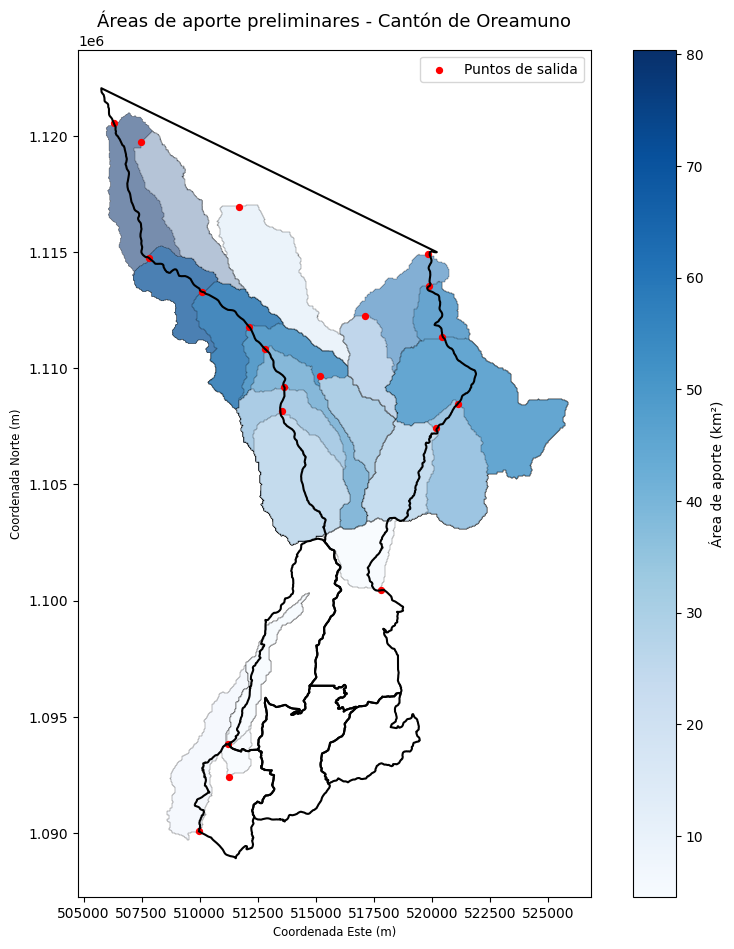

In [186]:
import matplotlib.pyplot as plt
import geopandas as gpd

fig, ax = plt.subplots(figsize=(11, 11))

# Áreas de aporte
areas_finales.plot(
    ax=ax,
    column="Area_km2",
    cmap="Blues",
    alpha=0.55,
    edgecolor="black",
    linewidth=0.35,
    legend=True,
    legend_kwds={"label": "Área de aporte (km²)"}
)

# Límite cantonal
limite_oreamuno.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5
)

# Puntos de salida
puntos_corregidos.plot(
    ax=ax,
    color="red",
    markersize=18,
    label="Puntos de salida"
)

ax.set_title(
    "Áreas de aporte preliminares - Cantón de Oreamuno",
    fontsize=13
)

ax.set_xlabel("Coordenada Este (m)")
ax.set_ylabel("Coordenada Norte (m)")
ax.legend()
ax.set_aspect("equal")

plt.show()

In [187]:

!pip install -q earthengine-api geemap


In [188]:

import ee
from google.colab import auth

auth.authenticate_user()
ee.Authenticate(auth_mode='colab', force=True)

print("Autenticación completada.")


Autenticación completada.


In [189]:

import ee

PROYECTO_GEE = "future-campaign-276316"

ee.Initialize(project=PROYECTO_GEE)

print("¡Google Earth Engine conectado correctamente!")


¡Google Earth Engine conectado correctamente!


In [190]:

import ee

# Colección CHIRPS diaria
chirps = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")

# Información general
fecha_inicio = ee.Date(
    chirps.aggregate_min("system:time_start")
).format("YYYY-MM-dd").getInfo()

fecha_final = ee.Date(
    chirps.aggregate_max("system:time_start")
).format("YYYY-MM-dd").getInfo()

cantidad = chirps.size().getInfo()

print("COLECCIÓN CHIRPS")
print("----------------------------")
print("Fecha inicial:", fecha_inicio)
print("Fecha final:", fecha_final)
print("Número de imágenes:", cantidad)
print("Variable: precipitation")
print("Unidad: mm/día")


COLECCIÓN CHIRPS
----------------------------
Fecha inicial: 1981-01-01
Fecha final: 2026-09-30
Número de imágenes: 16709
Variable: precipitation
Unidad: mm/día


In [191]:

import geopandas as gpd
import ee
import geemap

# Ruta del límite cantonal
ruta_limite = "/content/GeoAlerta_Oreamuno/01_Datos_Originales/Oreamuno_Canton.gpkg"

# Leer y reproyectar a coordenadas geográficas
limite_oreamuno = gpd.read_file(ruta_limite)
limite_oreamuno = limite_oreamuno.to_crs("EPSG:4326")

# Convertir la geometría a Google Earth Engine
geometria = limite_oreamuno.geometry.union_all()
geom_oreamuno = ee.Geometry(geometria.__geo_interface__)

# Filtrar CHIRPS para el cantón
chirps_oreamuno = chirps.filterBounds(geom_oreamuno)

print("LÍMITE CANTONAL CARGADO")
print("----------------------------")
print("Área:", round(geometria.area * 12364, 2), "km² aprox. (estimación)")
print("Imágenes CHIRPS:", chirps_oreamuno.size().getInfo())


LÍMITE CANTONAL CARGADO
----------------------------
Área: 206.9 km² aprox. (estimación)
Imágenes CHIRPS: 16709


In [192]:
import geopandas as gpd
import ee
import os
import requests

# Ruta del proyecto local
PROYECTO = "/content/GeoAlerta_Oreamuno"
ruta_limite = os.path.join(PROYECTO, "01_Datos_Originales", "Oreamuno_Canton.gpkg")

# Si la sesión expiró y el archivo no existe, lo regeneramos automáticamente
if not os.path.exists(ruta_limite):
    print("⚠️ El archivo local no existe. Recreando directorio y descargando datos...")
    os.makedirs(os.path.dirname(ruta_limite), exist_ok=True)

    # Descargar datos desde el FeatureServer
    URL_CANTONES = "https://services5.arcgis.com/4u1m1BBDkNDTVWsd/arcgis/rest/services/Cant%C3%B3n/FeatureServer/0/query"
    parametros = {"where": "1=1", "outFields": "*", "returnGeometry": "true", "outSR": "5367", "f": "geojson"}

    respuesta = requests.get(URL_CANTONES, params=parametros, timeout=120)
    respuesta.raise_for_status()
    cantones = gpd.GeoDataFrame.from_features(respuesta.json()["features"], crs="EPSG:5367")

    # Filtrar Oreamuno y exportarlo de nuevo
    oreamuno_temp = cantones[cantones["nom_cant"].str.upper() == "OREAMUNO"].copy()
    oreamuno_temp.to_file(ruta_limite, driver="GPKG")
    print("✅ Archivos temporales regenerados con éxito.")

# Cargar el límite cantonal
oreamuno = gpd.read_file(ruta_limite)

# Se verifica el sistema de coordenadas
print("CRS:", oreamuno.crs)

# Se calcula el área en km²
oreamuno_utm = oreamuno.to_crs(epsg=5367)
area_km2 = oreamuno_utm.geometry.area.sum() / 1_000_000

print(f"Área de estudio: {area_km2:.2f} km²")

# Se transforma a WGS84 para Google Earth Engine
oreamuno_wgs84 = oreamuno.to_crs(epsg=4326)

print("Límite cantonal cargado correctamente")

CRS: EPSG:5367
Área de estudio: 202.90 km²
Límite cantonal cargado correctamente


In [193]:

import os
import geopandas as gpd

# Ruta del límite cantonal
ruta_limite = "/content/GeoAlerta_Oreamuno/01_Datos_Originales/Oreamuno_Canton.gpkg"

# Verificar existencia del archivo
if not os.path.exists(ruta_limite):
    raise FileNotFoundError(f"No se encontró el archivo: {ruta_limite}")

# Cargar geometría
oreamuno = gpd.read_file(ruta_limite)

# Verificar información espacial
print("Sistema de coordenadas:", oreamuno.crs)
print("Número de entidades:", len(oreamuno))
print("Tipo de geometría:", oreamuno.geom_type.unique())

# Calcular superficie
oreamuno_utm = oreamuno.to_crs(epsg=5367)
area_km2 = oreamuno_utm.geometry.area.sum() / 1_000_000

print(f"Superficie: {area_km2:.2f} km²")

# Transformar a WGS84
oreamuno_wgs84 = oreamuno.to_crs(epsg=4326)

print("Proceso completado.")


Sistema de coordenadas: EPSG:5367
Número de entidades: 1
Tipo de geometría: ['Polygon']
Superficie: 202.90 km²
Proceso completado.


In [194]:
import ee
from google.colab import auth

# Intentar inicializar; si falla por credenciales, solicitar autenticación interactivamente
try:
    ee.Initialize(project="future-campaign-276316")
except Exception:
    print("🔑 Las credenciales no están activas. Iniciando proceso de autenticación...")
    try:
        auth.authenticate_user()
        ee.Authenticate(auth_mode='colab')
        ee.Initialize(project="future-campaign-276316")
        print("✅ Autenticado e inicializado correctamente.")
    except Exception as e:
        print("❌ Error durante el proceso de autenticación.")
        raise e

# Convertir el polígono de Oreamuno a Google Earth Engine
geometria = oreamuno_wgs84.geometry.iloc[0]

region_oreamuno = ee.Geometry(
    geometria.__geo_interface__
)

# Consultar colección CHIRPS Daily
chirps = (
    ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
    .filterBounds(region_oreamuno)
    .filterDate("1981-01-01", "2026-01-01")
)

# Verificar colección
print("Imágenes CHIRPS:", chirps.size().getInfo())

# Crear lista de años completos
anios = ee.List.sequence(1981, 2025)

# Calcular precipitación acumulada para cada año
def precipitacion_anual(anio):

    anio = ee.Number(anio)
    inicio = ee.Date.fromYMD(anio, 1, 1)
    fin = inicio.advance(1, "year")

    acumulado = (
        chirps.filterDate(inicio, fin)
        .sum()
        .rename("precipitacion_mm")
        .set("year", anio)
        .set("system:time_start", inicio.millis())
    )

    return acumulado

# Colección de precipitación anual
chirps_anual = ee.ImageCollection.fromImages(
    anios.map(precipitacion_anual)
)

# Promedio de precipitación anual 1981-2025
precipitacion_media = (
    chirps_anual.mean()
    .clip(region_oreamuno)
)

print("Años procesados:", chirps_anual.size().getInfo())
print("Climatología anual generada correctamente.")

Imágenes CHIRPS: 16436
Años procesados: 45
Climatología anual generada correctamente.


In [195]:

!pip install -q leafmap


In [196]:

# Estadísticas espaciales de precipitación media anual

estadisticas = precipitacion_media.reduceRegion(
    reducer=ee.Reducer.minMax().combine(
        reducer2=ee.Reducer.mean(),
        sharedInputs=True
    ).combine(
        reducer2=ee.Reducer.stdDev(),
        sharedInputs=True
    ),
    geometry=region_oreamuno,
    scale=5566,
    maxPixels=1e9
)

resultados = estadisticas.getInfo()

print("ESTADÍSTICAS DE PRECIPITACIÓN")
print("Periodo: 1981–2025")
print("--------------------------------")

for variable, valor in resultados.items():
    print(f"{variable}: {valor:.2f} mm/año")


ESTADÍSTICAS DE PRECIPITACIÓN
Periodo: 1981–2025
--------------------------------
precipitacion_mm_max: 3565.82 mm/año
precipitacion_mm_mean: 2452.02 mm/año
precipitacion_mm_min: 1595.92 mm/año
precipitacion_mm_stdDev: 638.31 mm/año


In [197]:

import ee
import pandas as pd
import matplotlib.pyplot as plt

# Periodo de análisis
anios = ee.List.sequence(1981, 2025)
meses = ee.List.sequence(1, 12)

# Calcular precipitación media acumulada por mes
def calcular_mes(mes):

    mes = ee.Number(mes)

    def acumulado_anual(anio):

        anio = ee.Number(anio)

        inicio = ee.Date.fromYMD(anio, mes, 1)
        fin = inicio.advance(1, "month")

        return (
            chirps.filterDate(inicio, fin)
            .sum()
            .rename("precipitacion")
        )

    # Promedio de los acumulados mensuales de 45 años
    imagen_mensual = ee.ImageCollection.fromImages(
        anios.map(acumulado_anual)
    ).mean()

    return imagen_mensual.set("mes", mes)


# Colección climatológica mensual
chirps_mensual = ee.ImageCollection.fromImages(
    meses.map(calcular_mes)
)

# Obtener promedio espacial para cada mes
def obtener_estadistica(mes):

    mes = ee.Number(mes)

    imagen = ee.Image(
        chirps_mensual.filter(
            ee.Filter.eq("mes", mes)
        ).first()
    )

    resultado = imagen.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=region_oreamuno,
        scale=5566,
        maxPixels=1e9
    )

    return ee.Feature(None, {
        "mes": mes,
        "precipitacion_mm": resultado.get("precipitacion")
    })


estadisticas_mensuales = ee.FeatureCollection(
    meses.map(obtener_estadistica)
)

datos = estadisticas_mensuales.getInfo()

# Organizar resultados
df_mensual = pd.DataFrame([
    {
        "Mes": f["properties"]["mes"],
        "Precipitacion_mm": f["properties"]["precipitacion_mm"]
    }
    for f in datos["features"]
])

nombres_meses = [
    "Ene", "Feb", "Mar", "Abr",
    "May", "Jun", "Jul", "Ago",
    "Sep", "Oct", "Nov", "Dic"
]

df_mensual["Nombre"] = nombres_meses

print(df_mensual[["Nombre", "Precipitacion_mm"]].round(2))


   Nombre  Precipitacion_mm
0     Ene            112.21
1     Feb             48.63
2     Mar             45.03
3     Abr            112.95
4     May            273.85
5     Jun            277.45
6     Jul            229.06
7     Ago            253.03
8     Sep            283.09
9     Oct            343.74
10    Nov            289.60
11    Dic            183.38


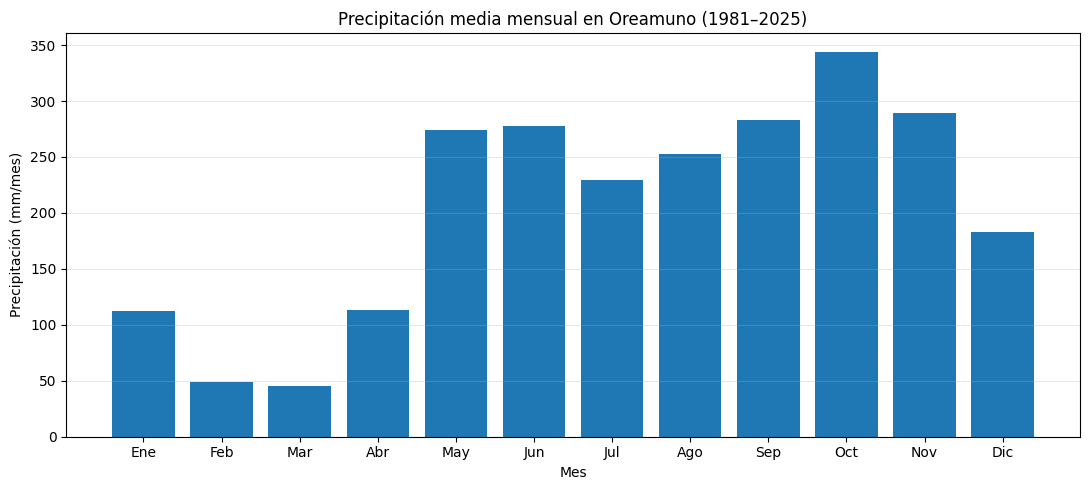

In [198]:

plt.figure(figsize=(11, 5))

plt.bar(
    df_mensual["Nombre"],
    df_mensual["Precipitacion_mm"]
)

plt.title(
    "Precipitación media mensual en Oreamuno (1981–2025)"
)

plt.xlabel("Mes")
plt.ylabel("Precipitación (mm/mes)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


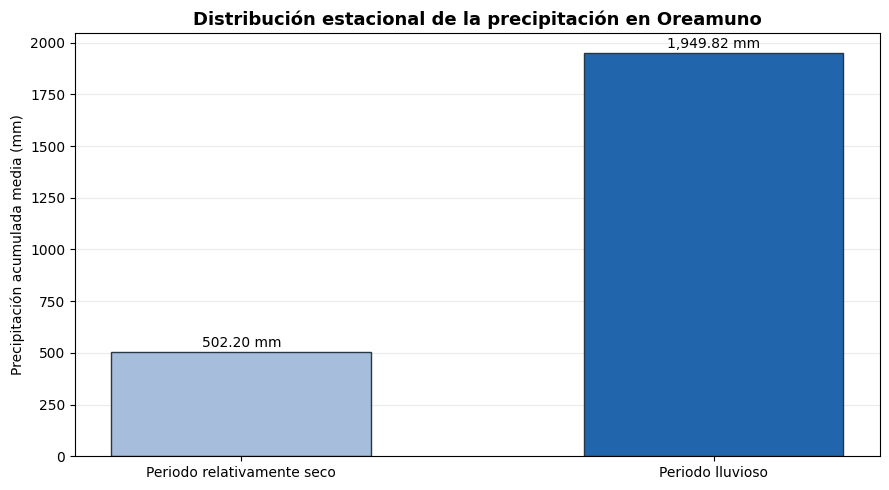

In [199]:

import matplotlib.pyplot as plt

periodos = ["Periodo relativamente seco", "Periodo lluvioso"]
valores = [502.20, 1949.82]

plt.figure(figsize=(9, 5))

barras = plt.bar(
    periodos,
    valores,
    color=["#a6bddb", "#2166ac"],
    edgecolor="#263746",
    width=0.55
)

for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width()/2,
        altura + 25,
        f"{altura:,.2f} mm",
        ha="center",
        fontsize=10
    )

plt.title(
    "Distribución estacional de la precipitación en Oreamuno",
    fontsize=13,
    fontweight="bold"
)

plt.ylabel("Precipitación acumulada media (mm)")
plt.grid(axis="y", alpha=0.25)
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()


In [200]:

import ee
import pandas as pd
import numpy as np

# Periodo de análisis
ANIO_INICIO = 1981
ANIO_FIN = 2025

# Lista para almacenar resultados
registros = []

# Procesamiento por bloques de cinco años
for inicio in range(ANIO_INICIO, ANIO_FIN + 1, 5):

    fin = min(inicio + 5, ANIO_FIN + 1)

    print(f"Procesando {inicio}-{fin-1}...")

    coleccion = (
        chirps
        .filterDate(f"{inicio}-01-01", f"{fin}-01-01")
        .sort("system:time_start")
    )

    # Calcular precipitación media diaria sobre Oreamuno
    def calcular_media(img):

        media = img.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=region_oreamuno,
            scale=5566,
            maxPixels=1e9,
            tileScale=4
        ).get("precipitation")

        return img.set({
            "fecha": ee.Date(
                img.get("system:time_start")
            ).format("YYYY-MM-dd"),
            "lluvia_media": media
        })

    serie_ee = coleccion.map(calcular_media)

    # Recuperar fechas y valores
    datos = ee.Dictionary({
        "fechas": serie_ee.aggregate_array("fecha"),
        "lluvia": serie_ee.aggregate_array("lluvia_media")
    }).getInfo()

    registros.extend(
        zip(datos["fechas"], datos["lluvia"])
    )

# Crear DataFrame
df_diario = pd.DataFrame(
    registros,
    columns=["Fecha", "Precipitacion_mm"]
)

df_diario["Fecha"] = pd.to_datetime(df_diario["Fecha"])

df_diario = (
    df_diario
    .dropna()
    .sort_values("Fecha")
    .drop_duplicates(subset="Fecha")
    .reset_index(drop=True)
)

print("\nSerie diaria generada correctamente.")
print("Registros:", len(df_diario))
print("Periodo:", df_diario["Fecha"].min(),
      "a", df_diario["Fecha"].max())

df_diario.head()


Procesando 1981-1985...
Procesando 1986-1990...
Procesando 1991-1995...
Procesando 1996-2000...
Procesando 2001-2005...
Procesando 2006-2010...
Procesando 2011-2015...
Procesando 2016-2020...
Procesando 2021-2025...

Serie diaria generada correctamente.
Registros: 16436
Periodo: 1981-01-01 00:00:00 a 2025-12-31 00:00:00


,Fecha,Precipitacion_mm
0,1981-01-01,29.323301
1,1981-01-02,11.561878
2,1981-01-03,10.642184
3,1981-01-04,18.720397
4,1981-01-05,0.000000


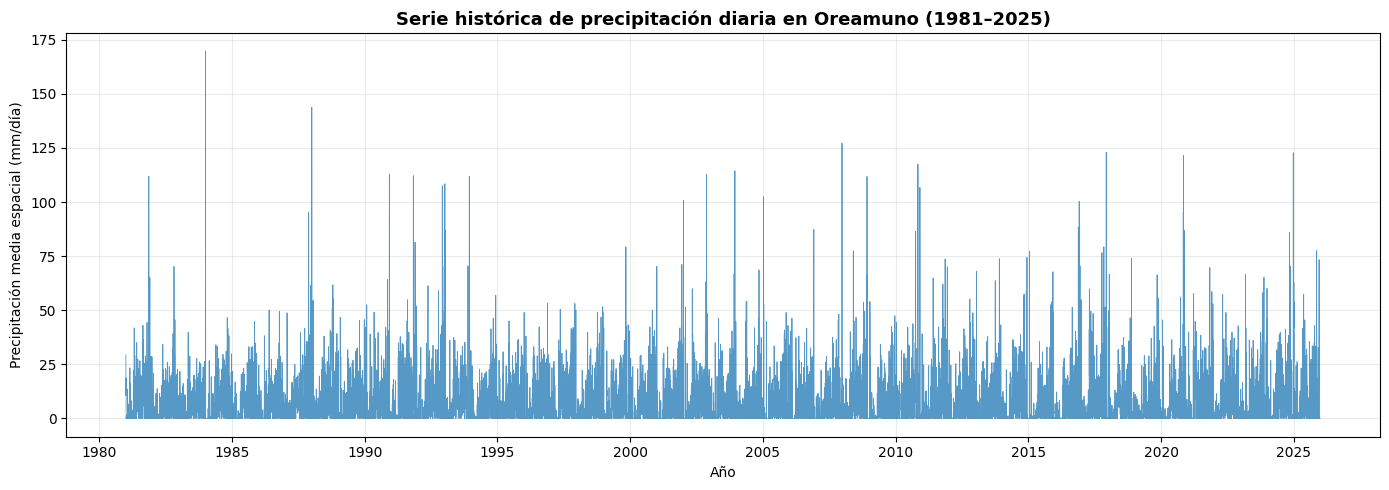

In [201]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    df_diario["Fecha"],
    df_diario["Precipitacion_mm"],
    linewidth=0.6,
    alpha=0.75
)

plt.title(
    "Serie histórica de precipitación diaria en Oreamuno (1981–2025)",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Año")
plt.ylabel("Precipitación media espacial (mm/día)")

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [202]:
# Revisar estructura de la serie histórica diaria
print(df_diario.info())

display(df_diario.head())
print(df_diario.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16436 entries, 0 to 16435
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Fecha             16436 non-null  datetime64[ns]
 1   Precipitacion_mm  16436 non-null  float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 256.9 KB
None


,Fecha,Precipitacion_mm
0,1981-01-01,29.323301
1,1981-01-02,11.561878
2,1981-01-03,10.642184
3,1981-01-04,18.720397
4,1981-01-05,0.000000


['Fecha', 'Precipitacion_mm']


In [203]:
# Cálculo de indicadores de precipitación diaria
p95 = df_diario["Precipitacion_mm"].quantile(0.95)
p99 = df_diario["Precipitacion_mm"].quantile(0.99)

precipitacion_max = df_diario["Precipitacion_mm"].max()
precipitacion_media = df_diario["Precipitacion_mm"].mean()

print("INDICADORES DE PRECIPITACIÓN DIARIA")
print("-----------------------------------")
print(f"Precipitación media: {precipitacion_media:.2f} mm")
print(f"Percentil 95 (P95): {p95:.2f} mm")
print(f"Percentil 99 (P99): {p99:.2f} mm")
print(f"Máximo diario: {precipitacion_max:.2f} mm")

INDICADORES DE PRECIPITACIÓN DIARIA
-----------------------------------
Precipitación media: 6.72 mm
Percentil 95 (P95): 26.04 mm
Percentil 99 (P99): 46.13 mm
Máximo diario: 169.73 mm


In [204]:
# Clasificación de los registros diarios
df_diario["Clasificacion"] = "Habitual"

df_diario.loc[
    df_diario["Precipitacion_mm"] > p95,
    "Clasificacion"
] = "Extremo (P95)"

df_diario.loc[
    df_diario["Precipitacion_mm"] > p99,
    "Clasificacion"
] = "Muy extremo (P99)"

# Resumen de registros por categoría
print(df_diario["Clasificacion"].value_counts())

Clasificacion
Habitual             15614
Extremo (P95)          657
Muy extremo (P99)      165
Name: count, dtype: int64


In [205]:
# Seleccionar los eventos que superan el percentil 99
eventos_extremos = df_diario[
    df_diario["Precipitacion_mm"] > p99
].copy()

# Ordenar de mayor a menor precipitación
eventos_extremos = eventos_extremos.sort_values(
    "Precipitacion_mm",
    ascending=False
)

# Mostrar los 20 eventos más intensos
display(eventos_extremos.head(20))

,Fecha,Precipitacion_mm,Clasificacion
1096,1984-01-02,169.731878,Muy extremo (P99)
2558,1988-01-03,143.780158,Muy extremo (P99)
9854,2007-12-25,127.219913,Muy extremo (P99)
13490,2017-12-08,122.936727,Muy extremo (P99)
16064,2024-12-25,122.774883,Muy extremo (P99)
14553,2020-11-05,121.550532,Muy extremo (P99)
10898,2010-11-03,117.588527,Muy extremo (P99)
8380,2003-12-12,114.477942,Muy extremo (P99)
10899,2010-11-04,113.542206,Muy extremo (P99)
3626,1990-12-06,112.988025,Muy extremo (P99)


In [206]:
# Seleccionar días que superan el umbral P95
dias_extremos = df_diario[
    df_diario["Precipitacion_mm"] > p95
].copy()

# Ordenar cronológicamente
dias_extremos = dias_extremos.sort_values("Fecha")

# Identificar interrupciones entre días extremos
dias_extremos["Diferencia"] = (
    dias_extremos["Fecha"].diff().dt.days
)

# Crear identificador para cada episodio
dias_extremos["Episodio"] = (
    dias_extremos["Diferencia"].ne(1)
).cumsum()

# Resumir los episodios identificados
episodios = dias_extremos.groupby("Episodio").agg(
    Fecha_inicio=("Fecha", "min"),
    Fecha_fin=("Fecha", "max"),
    Duracion_dias=("Fecha", "count"),
    Precipitacion_acumulada=("Precipitacion_mm", "sum"),
    Precipitacion_maxima=("Precipitacion_mm", "max")
).reset_index(drop=True)

# Ordenar por precipitación acumulada
episodios = episodios.sort_values(
    "Precipitacion_acumulada",
    ascending=False
)

display(episodios.head(20).round(2))

,Fecha_inicio,Fecha_fin,Duracion_dias,Precipitacion_acumulada,Precipitacion_maxima
421,2010-11-02,2010-11-05,4,350.94,117.59
655,2024-12-29,2025-01-04,7,293.55,62.87
431,2011-10-11,2011-10-16,6,268.76,62.01
112,1990-12-04,1990-12-06,3,237.87,112.99
600,2022-04-25,2022-04-28,4,179.56,57.22
151,1992-12-03,1992-12-04,2,177.00,107.48
316,2003-12-11,2003-12-12,2,175.96,114.48
29,1984-01-02,1984-01-02,1,169.73,169.73
369,2007-11-07,2007-11-11,5,165.58,48.17
577,2020-11-05,2020-11-06,2,162.75,121.55


In [207]:
# Incorporar el año de inicio de cada episodio
episodios["Anio"] = episodios["Fecha_inicio"].dt.year

# Contabilizar episodios por año
frecuencia_anual = (
    episodios.groupby("Anio")
    .size()
    .reset_index(name="Cantidad_episodios")
)

# Ordenar cronológicamente
frecuencia_anual = frecuencia_anual.sort_values("Anio")

display(frecuencia_anual)

,Anio,Cantidad_episodios
0,1981,17
1,1982,6
2,1983,6
3,1984,14
4,1985,8
5,1986,7
6,1987,12
7,1988,18
8,1989,12
9,1990,13


In [208]:
# Extraer el mes de inicio de cada episodio
episodios["Mes"] = episodios["Fecha_inicio"].dt.month

nombres_meses = {
    1: "Enero", 2: "Febrero", 3: "Marzo",
    4: "Abril", 5: "Mayo", 6: "Junio",
    7: "Julio", 8: "Agosto", 9: "Septiembre",
    10: "Octubre", 11: "Noviembre", 12: "Diciembre"
}

# Contabilizar episodios por mes
frecuencia_mensual = (
    episodios.groupby("Mes")
    .size()
    .reindex(range(1, 13), fill_value=0)
    .reset_index(name="Cantidad_episodios")
)

frecuencia_mensual["Nombre_mes"] = (
    frecuencia_mensual["Mes"].map(nombres_meses)
)

display(frecuencia_mensual)

,Mes,Cantidad_episodios,Nombre_mes
0,1,39,Enero
1,2,9,Febrero
2,3,13,Marzo
3,4,26,Abril
4,5,77,Mayo
5,6,53,Junio
6,7,38,Julio
7,8,45,Agosto
8,9,51,Septiembre
9,10,123,Octubre


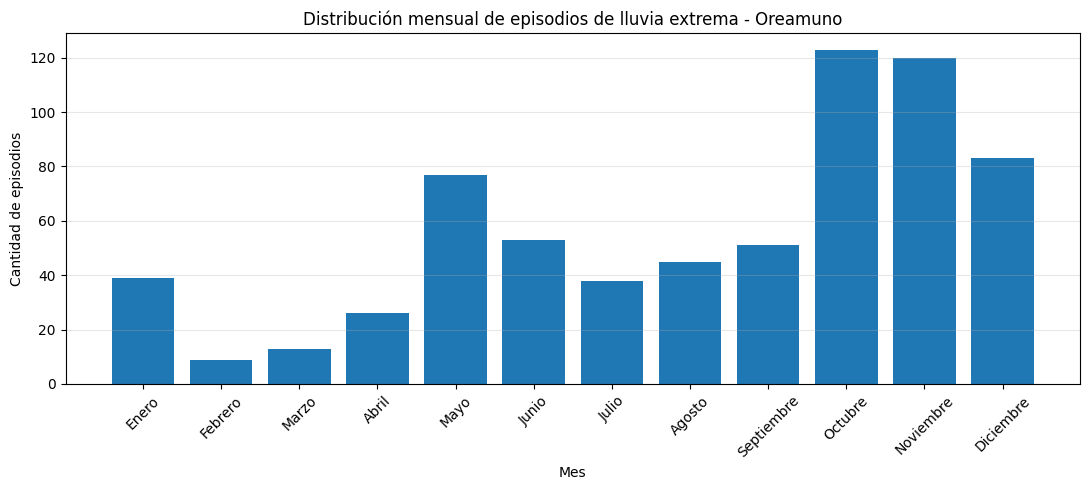

In [209]:
plt.figure(figsize=(11, 5))

plt.bar(
    frecuencia_mensual["Nombre_mes"],
    frecuencia_mensual["Cantidad_episodios"]
)

plt.title("Distribución mensual de episodios de lluvia extrema - Oreamuno")
plt.xlabel("Mes")
plt.ylabel("Cantidad de episodios")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [210]:
# Crear catálogo histórico de episodios
catalogo_eventos = episodios.copy()

# Generar identificador único
catalogo_eventos.insert(
    0, "ID_evento",
    ["ORE-" + str(i).zfill(4)
     for i in range(1, len(catalogo_eventos) + 1)]
)

# Incorporar información temporal
catalogo_eventos["Anio"] = (
    catalogo_eventos["Fecha_inicio"].dt.year
)

catalogo_eventos["Mes"] = (
    catalogo_eventos["Fecha_inicio"].dt.month
)

# Clasificar episodios según su máxima precipitación diaria
catalogo_eventos["Categoria"] = catalogo_eventos[
    "Precipitacion_maxima"
].apply(
    lambda x: "Muy extremo (P99)" if x > p99
    else "Extremo (P95)"
)

# Campos para la verificación documental
catalogo_eventos["Tipo_incidente"] = None
catalogo_eventos["Localidad"] = None
catalogo_eventos["Fuente"] = None
catalogo_eventos["URL_fuente"] = None
catalogo_eventos["Estado_verificacion"] = "Pendiente"

# Exportar catálogo
catalogo_eventos.to_csv(
    "GeoAlerta_Oreamuno_Catalogo_Eventos.csv",
    index=False,
    encoding="utf-8-sig"
)

display(catalogo_eventos.head(10))

print("Total de episodios:", len(catalogo_eventos))
print("Catálogo exportado correctamente.")

,ID_evento,Fecha_inicio,Fecha_fin,Duracion_dias,Precipitacion_acumulada,Precipitacion_maxima,Anio,Mes,Categoria,Tipo_incidente,Localidad,Fuente,URL_fuente,Estado_verificacion
421,ORE-0001,2010-11-02,2010-11-05,4,350.942667,117.588527,2010,11,Muy extremo (P99),None,None,None,None,Pendiente
655,ORE-0002,2024-12-29,2025-01-04,7,293.549935,62.867517,2024,12,Muy extremo (P99),None,None,None,None,Pendiente
431,ORE-0003,2011-10-11,2011-10-16,6,268.761538,62.013326,2011,10,Muy extremo (P99),None,None,None,None,Pendiente
112,ORE-0004,1990-12-04,1990-12-06,3,237.868904,112.988025,1990,12,Muy extremo (P99),None,None,None,None,Pendiente
600,ORE-0005,2022-04-25,2022-04-28,4,179.561954,57.222835,2022,4,Muy extremo (P99),None,None,None,None,Pendiente
151,ORE-0006,1992-12-03,1992-12-04,2,176.997958,107.475139,1992,12,Muy extremo (P99),None,None,None,None,Pendiente
316,ORE-0007,2003-12-11,2003-12-12,2,175.964931,114.477942,2003,12,Muy extremo (P99),None,None,None,None,Pendiente
29,ORE-0008,1984-01-02,1984-01-02,1,169.731878,169.731878,1984,1,Muy extremo (P99),None,None,None,None,Pendiente
369,ORE-0009,2007-11-07,2007-11-11,5,165.578689,48.171413,2007,11,Muy extremo (P99),None,None,None,None,Pendiente
577,ORE-0010,2020-11-05,2020-11-06,2,162.750783,121.550532,2020,11,Muy extremo (P99),None,None,None,None,Pendiente


Total de episodios: 677
Catálogo exportado correctamente.


In [211]:
# Ordenar episodios del más reciente al más antiguo
catalogo_eventos = catalogo_eventos.sort_values(
    by="Fecha_inicio",
    ascending=False
).reset_index(drop=True)

# Mostrar catálogo ordenado
display(catalogo_eventos)

,ID_evento,Fecha_inicio,Fecha_fin,Duracion_dias,Precipitacion_acumulada,Precipitacion_maxima,Anio,Mes,Categoria,Tipo_incidente,Localidad,Fuente,URL_fuente,Estado_verificacion
0,ORE-0089,2025-12-15,2025-12-15,1,73.355001,73.355001,2025,12,Muy extremo (P99),None,None,None,None,Pendiente
1,ORE-0408,2025-12-02,2025-12-02,1,32.843233,32.843233,2025,12,Extremo (P95),None,None,None,None,Pendiente
2,ORE-0078,2025-11-11,2025-11-11,1,77.535235,77.535235,2025,11,Muy extremo (P99),None,None,None,None,Pendiente
3,ORE-0632,2025-11-01,2025-11-01,1,26.967035,26.967035,2025,11,Extremo (P95),None,None,None,None,Pendiente
4,ORE-0384,2025-10-21,2025-10-21,1,33.602333,33.602333,2025,10,Extremo (P95),None,None,None,None,Pendiente
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
672,ORE-0611,1981-06-14,1981-06-14,1,27.424862,27.424862,1981,6,Extremo (P95),None,None,None,None,Pendiente
673,ORE-0348,1981-05-30,1981-05-30,1,35.046295,35.046295,1981,5,Extremo (P95),None,None,None,None,Pendiente
674,ORE-0521,1981-05-04,1981-05-04,1,29.179023,29.179023,1981,5,Extremo (P95),None,None,None,None,Pendiente
675,ORE-0247,1981-04-26,1981-04-26,1,41.832719,41.832719,1981,4,Extremo (P95),None,None,None,None,Pendiente


In [212]:
catalogo_eventos.to_csv(
    "GeoAlerta_Oreamuno_Catalogo_Eventos.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Catálogo ordenado y exportado correctamente.")

Catálogo ordenado y exportado correctamente.


In [213]:
# Identificar variables relacionadas con los datos espaciales
palabras_clave = [
    "cuenca", "oreamuno", "chirps", "dem",
    "precip", "raster", "gdf", "limite",
    "cobertura", "rio", "drenaje", "red"
]

for nombre, variable in sorted(globals().items()):
    if any(p in nombre.lower() for p in palabras_clave):
        print(f"{nombre}: {type(variable).__name__}")

chirps: ImageCollection
chirps_anual: ImageCollection
chirps_mensual: ImageCollection
chirps_oreamuno: ImageCollection
crs_dem: CRS
cuenca: Raster
cuenca_indice: Raster
cuenca_prueba: Raster
dem: Raster
dem_acondicionado: Raster
dem_pysheds: Raster
dem_ref: DatasetReader
dem_relleno: Raster
dem_sin_pozos: Raster
df_diario: DataFrame
distritos_oreamuno: GeoDataFrame
geom_oreamuno: Geometry
geometria_oreamuno: Polygon
limite: Polygon
limite_4326: GeoDataFrame
limite_oreamuno: GeoDataFrame
limite_temp: GeoDataFrame
limite_wgs84: GeoDataFrame
obtener_dem: function
oreamuno: GeoDataFrame
oreamuno_temp: GeoDataFrame
oreamuno_utm: GeoDataFrame
oreamuno_wgs84: GeoDataFrame
perfil_dem: Profile
periodos: list
precipitacion_anual: function
precipitacion_max: float
precipitacion_media: float64
punto_red: Point
rasterio: module
rasterize: function
red: GeoDataFrame
red_500: GeoDataFrame
red_completa: GeoDataFrame
red_geojson: FeatureCollection
red_geojson_500: FeatureCollection
red_proj: GeoDataFra

In [214]:
# Inspeccionar colección anual CHIRPS
print("Cantidad de imágenes:", chirps_anual.size().getInfo())

primera_imagen = ee.Image(chirps_anual.first())

print("Bandas:", primera_imagen.bandNames().getInfo())

print("Propiedades:")
print(primera_imagen.toDictionary().getInfo())

Cantidad de imágenes: 45
Bandas: ['precipitacion_mm']
Propiedades:
{'year': 1981}


In [217]:

# Inventario de archivos ráster disponibles en el entorno

import os

for carpeta in ["/content", "/content/drive/MyDrive"]:
    if os.path.exists(carpeta):
        print(f"\n--- {carpeta} ---")
        for raiz, dirs, archivos in os.walk(carpeta):
            dirs[:] = [d for d in dirs if d not in [
                ".ipynb_checkpoints", "node_modules"
            ]]
            for archivo in archivos:
                if archivo.lower().endswith((
                    ".tif", ".tiff", ".img", ".asc"
                )):
                    print(os.path.join(raiz, archivo))



--- /content ---
/content/GeoAlerta_Oreamuno/01_Datos_Originales/Oreamuno_Copernicus_GLO30.tif
/content/GeoAlerta_Oreamuno/02_Exposicion_Territorial/Oreamuno_Poblacion_Recortada.tif
/content/GeoAlerta_Oreamuno/02_Datos_Procesados/Oreamuno_Copernicus_GLO30_CRTM05.tif
/content/GeoAlerta_Oreamuno/02_Datos_Procesados/Oreamuno_Hillshade.tif
/content/GeoAlerta_Oreamuno/02_Datos_Procesados/Oreamuno_Pendiente_grados.tif
/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Direccion_Flujo_D8.tif
/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_DEM_Acondicionado.tif
/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Susceptibilidad_Proximidad_Drenaje.tif
/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Acumulacion_Flujo.tif
/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Susceptibilidad_Acumulacion_Flujo.tif
/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Distancia_Drenaje.tif


In [ ]:

import rasterio
import os

carpeta = "/content/GeoAlerta_Oreamuno"

archivos = {
    "DEM proyectado": "02_Datos_Procesados/Oreamuno_Copernicus_GLO30_CRTM05.tif",
    "Pendiente": "02_Datos_Procesados/Oreamuno_Pendiente_grados.tif",
    "Dirección de flujo": "03_Modelos_Hidrologicos/Oreamuno_Direccion_Flujo_D8.tif",
    "Acumulación de flujo": "03_Modelos_Hidrologicos/Oreamuno_Acumulacion_Flujo.tif"
}

for nombre, ruta in archivos.items():
    archivo = os.path.join(carpeta, ruta)

    with rasterio.open(archivo) as src:
        print(f"\n--- {nombre} ---")
        print("CRS:", src.crs)
        print("Resolución:", src.res)
        print("Dimensiones:", src.width, "x", src.height)
        print("NoData:", src.nodata)
        print("Mínimo:", src.read(1, masked=True).min())
        print("Máximo:", src.read(1, masked=True).max())


In [ ]:

import rasterio
import os

archivos = {
    "DEM": "02_Datos_Procesados/Oreamuno_Copernicus_GLO30_CRTM05.tif",
    "Pendiente": "02_Datos_Procesados/Oreamuno_Pendiente_grados.tif",
    "Dirección": "03_Modelos_Hidrologicos/Oreamuno_Direccion_Flujo_D8.tif",
    "Acumulación": "03_Modelos_Hidrologicos/Oreamuno_Acumulacion_Flujo.tif"
}

carpeta = "/content/GeoAlerta_Oreamuno"
referencia = None

for nombre, ruta in archivos.items():
    with rasterio.open(os.path.join(carpeta, ruta)) as src:
        print(f"\n{nombre}")
        print("Transform:", src.transform)
        print("Extensión:", src.bounds)
        print("Tipo de dato:", src.dtypes[0])

        if referencia is None:
            referencia = (src.transform, src.bounds, src.shape)
        else:
            print("¿Alineado con DEM?:",
                  referencia == (src.transform, src.bounds, src.shape))


In [239]:
# SUELOS


import rasterio

url_suelos = (
    "https://data.naturalcapitalalliance.stanford.edu/download/"
    "global/HYSOGs250m/HYSOGs250m_Soil_Groups_reclassified.tif"
)

try:
    with rasterio.open(url_suelos) as src:
        print("HYSOGs250m: conexión correcta")
        print("CRS:", src.crs)
        print("Resolución:", src.res)
        print("Dimensiones:", src.width, "x", src.height)
        print("NoData:", src.nodata)
        print("Extensión:", src.bounds)
        print("Tipo de dato:", src.dtypes[0])

except Exception as e:
    print("No se pudo acceder al ráster:")
    print(e)


HYSOGs250m: conexión correcta
CRS: EPSG:4326
Resolución: (0.002083333, 0.002083333)
Dimensiones: 172800 x 67200
NoData: 255.0
Extensión: BoundingBox(left=-180.0, bottom=-56.00081039400003, right=179.9999424, top=83.999167206)
Tipo de dato: uint8


In [219]:
import ee

# Cargar la colección global ESA WorldCover 10m v200
# Filtramos por el límite cantonal de Oreamuno (region_oreamuno ya definida en el entorno)
worldcover = ee.ImageCollection("ESA/WorldCover/v200").first().clip(region_oreamuno)

print("Cobertura disponible:")
print(type(worldcover))

print("\nInformación de las bandas de WorldCover:")
print(worldcover.bandNames().getInfo())

Cobertura disponible:
<class 'ee.image.Image'>

Información de las bandas de WorldCover:
['Map']


In [220]:
import ee

estadisticas_wc = worldcover.reduceRegion(
    reducer=ee.Reducer.frequencyHistogram(),
    geometry=geom_oreamuno,
    scale=10,
    maxPixels=1e10,
    tileScale=4
)

clases_wc = estadisticas_wc.get('Map').getInfo()

print("CLASES DE COBERTURA EN OREAMUNO\n")

total = sum(clases_wc.values())

for clase, cantidad in sorted(clases_wc.items()):
    porcentaje = cantidad / total * 100
    print(
        f"Clase {clase}: {cantidad:,.0f} píxeles "
        f"({porcentaje:.2f}%)"
    )

print("\nTotal de píxeles:", f"{total:,.0f}")

CLASES DE COBERTURA EN OREAMUNO

Clase 10: 1,573,224 píxeles (75.87%)
Clase 20: 7 píxeles (0.00%)
Clase 30: 340,444 píxeles (16.42%)
Clase 40: 84,759 píxeles (4.09%)
Clase 50: 59,979 píxeles (2.89%)
Clase 60: 13,897 píxeles (0.67%)
Clase 80: 1,362 píxeles (0.07%)

Total de píxeles: 2,073,672


In [221]:
import geemap
import ee

Map = geemap.Map()

Map.centerObject(geom_oreamuno, 11)

# Convertir el límite de Oreamuno a Earth Engine
limite_ee_mapa = geemap.gdf_to_ee(limite_oreamuno)

# Visualización de WorldCover
vis_wc = {
    'min': 10,
    'max': 100,
    'palette': [
        '006400', 'ffbb22', 'ffff4c',
        'f096ff', 'fa0000', 'b4b4b4',
        'f0f0f0', '0064c8', '0096a0',
        '00cf75', 'fae6a0'
    ]
}

Map.addLayer(worldcover, vis_wc, 'ESA WorldCover 2021')

# Agregar límite cantonal
Map.addLayer(
    limite_ee_mapa.style(
        color='000000',
        fillColor='00000000',
        width=2
    ),
    {},
    'Límite de Oreamuno'
)

Map.addLayerControl()
Map

Map(center=[10.007992000352134, -83.86583995214541], controls=(WidgetControl(options=['position', 'transparent…

In [222]:
Map = geemap.Map()

# Mapa base satelital
Map.add_basemap('SATELLITE')

Map.centerObject(geom_oreamuno, 11)

In [223]:
Map.addLayer(
    worldcover.visualize(**vis_wc, opacity=0.55),
    {},
    'ESA WorldCover 2021'
)

In [224]:
import geemap
import ee

# Crear mapa interactivo
Map = geemap.Map()

# Mapa base satelital
Map.add_basemap('SATELLITE')

# Centrar en Oreamuno
Map.centerObject(geom_oreamuno, 11)

# Convertir límite cantonal a Earth Engine
limite_ee_mapa = geemap.gdf_to_ee(limite_oreamuno)

# Simbología WorldCover 2021
vis_wc = {
    'min': 10,
    'max': 100,
    'palette': [
        '006400',  # Árboles
        'ffbb22',  # Matorral
        'ffff4c',  # Pastizales
        'f096ff',  # Cultivos
        'fa0000',  # Urbano
        'b4b4b4',  # Suelo desnudo
        'f0f0f0',  # Nieve y hielo
        '0064c8',  # Agua
        '0096a0',  # Humedales
        '00cf75',  # Manglares
        'fae6a0'   # Musgos y líquenes
    ]
}

# Agregar cobertura con transparencia
Map.addLayer(
    worldcover.visualize(**vis_wc, opacity=0.55),
    {},
    'ESA WorldCover 2021'
)

# Agregar límite de Oreamuno
Map.addLayer(
    limite_ee_mapa.style(
        color='FFFFFF',
        fillColor='00000000',
        width=2
    ),
    {},
    'Límite de Oreamuno'
)

# Control de capas
Map.addLayerControl()

# Mostrar mapa
Map

Map(center=[10.007992000352134, -83.86583995214541], controls=(WidgetControl(options=['position', 'transparent…

In [225]:
# Tabla de correspondencia

import pandas as pd

correspondencia = pd.DataFrame({
    'Codigo_WorldCover': [10, 20, 30, 40, 50, 60, 80],
    'Cobertura_WorldCover': [
        'Arboles',
        'Matorral',
        'Pastizales',
        'Cultivos',
        'Construido',
        'Suelo desnudo',
        'Agua permanente'
    ],
    'Categoria_SCS': [
        'Bosque',
        'Matorral',
        'Pastura',
        'Cultivos',
        'Area urbana',
        'Suelo desnudo',
        'Agua'
    ],
    'Aplicacion_CN': [
        'Bosque',
        'Matorral',
        'Pastura o pastizal',
        'Cultivos agricolas',
        'Superficie urbana',
        'Suelo desnudo',
        'Excluir del calculo terrestre'
    ]
})

display(correspondencia)

,Codigo_WorldCover,Cobertura_WorldCover,Categoria_SCS,Aplicacion_CN
0,10,Arboles,Bosque,Bosque
1,20,Matorral,Matorral,Matorral
2,30,Pastizales,Pastura,Pastura o pastizal
3,40,Cultivos,Cultivos,Cultivos agricolas
4,50,Construido,Area urbana,Superficie urbana
5,60,Suelo desnudo,Suelo desnudo,Suelo desnudo
6,80,Agua permanente,Agua,Excluir del calculo terrestre


In [226]:
import pandas as pd

datos_cn = {
    'Codigo_WorldCover': [10, 20, 30, 40, 50, 60],
    'Cobertura': [
        'Arboles',
        'Matorral',
        'Pastizales',
        'Cultivos',
        'Construido',
        'Suelo desnudo'
    ],
    'Condicion': [
        'Bosque bueno',
        'Matorral regular',
        'Pastura regular',
        'Cultivo bueno',
        'Impermeable',
        'Suelo desnudo'
    ],
    'CN_B': [55, 56, 69, 78, 98, 86],
    'CN_C': [70, 70, 79, 85, 98, 91],
    'CN_D': [77, 77, 84, 89, 98, 94]
}

tabla_cn = pd.DataFrame(datos_cn)

display(tabla_cn)

,Codigo_WorldCover,Cobertura,Condicion,CN_B,CN_C,CN_D
0,10,Arboles,Bosque bueno,55,70,77
1,20,Matorral,Matorral regular,56,70,77
2,30,Pastizales,Pastura regular,69,79,84
3,40,Cultivos,Cultivo bueno,78,85,89
4,50,Construido,Impermeable,98,98,98
5,60,Suelo desnudo,Suelo desnudo,86,91,94


In [227]:
import pandas as pd

datos_cn = {
    'Codigo_WorldCover': [10, 20, 30, 40, 50, 60],
    'Cobertura': [
        'Arboles',
        'Matorral',
        'Pastizales',
        'Cultivos',
        'Construido',
        'Suelo desnudo'
    ],
    'Condicion': [
        'Bosque bueno',
        'Matorral regular',
        'Pastura regular',
        'Cultivo bueno',
        'Impermeable',
        'Suelo desnudo'
    ],
    'CN_B': [55, 56, 69, 78, 98, 86],
    'CN_C': [70, 70, 79, 85, 98, 91],
    'CN_D': [77, 77, 84, 89, 98, 94]
}

tabla_cn = pd.DataFrame(datos_cn)

display(tabla_cn)

,Codigo_WorldCover,Cobertura,Condicion,CN_B,CN_C,CN_D
0,10,Arboles,Bosque bueno,55,70,77
1,20,Matorral,Matorral regular,56,70,77
2,30,Pastizales,Pastura regular,69,79,84
3,40,Cultivos,Cultivo bueno,78,85,89
4,50,Construido,Impermeable,98,98,98
5,60,Suelo desnudo,Suelo desnudo,86,91,94


In [231]:
import ee
import requests
import rasterio
import numpy as np
from rasterio.io import MemoryFile
from rasterio.warp import reproject, Resampling

# Geometría del cantón
region = geom_oreamuno

# Descargar WorldCover recortado
url_wc = worldcover.clip(region).getDownloadURL({
    'scale': 10,
    'crs': 'EPSG:4326',
    'region': region,
    'format': 'GEO_TIFF'
})

respuesta = requests.get(url_wc)
respuesta.raise_for_status()

print("Descarga de WorldCover completada.")
print("Tamaño:", len(respuesta.content) / 1024 / 1024, "MB")

Descarga de WorldCover completada.
Tamaño: 0.24636363983154297 MB


In [232]:
from rasterio.io import MemoryFile
import numpy as np

with MemoryFile(respuesta.content) as memfile:
    with memfile.open() as src:

        worldcover_descargado = src.read(1)

        print("INFORMACIÓN DE WORLDCOVER\n")
        print("CRS:", src.crs)
        print("Resolución:", src.res)
        print("Dimensiones:", src.width, "x", src.height)
        print("NoData:", src.nodata)

        valores, cantidades = np.unique(
            worldcover_descargado,
            return_counts=True
        )

        print("\nClases descargadas:")
        for valor, cantidad in zip(valores, cantidades):
            print(f"Clase {valor}: {cantidad:,} píxeles")

INFORMACIÓN DE WORLDCOVER

CRS: EPSG:4326
Resolución: (8.983152841195215e-05, 8.983152841195215e-05)
Dimensiones: 1639 x 3338
NoData: 0.0

Clases descargadas:
Clase 10: 4,077,640 píxeles
Clase 20: 22 píxeles
Clase 30: 899,207 píxeles
Clase 40: 183,696 píxeles
Clase 50: 261,817 píxeles
Clase 60: 45,837 píxeles
Clase 80: 2,762 píxeles
Clase 90: 1 píxeles


In [233]:
import rasterio
import numpy as np
from rasterio.io import MemoryFile
from rasterio.warp import reproject, Resampling

salida_wc = (
    '/content/GeoAlerta_Oreamuno/02_Datos_Procesados/'
    'Oreamuno_WorldCover_2021_CRTM05.tif'
)

with rasterio.open(ruta_dem_proyectado) as dem:

    perfil = dem.profile.copy()

    # Crear ráster de destino con la cuadrícula del DEM
    worldcover_alineado = np.zeros(
        (dem.height, dem.width),
        dtype=np.uint8
    )

    with MemoryFile(respuesta.content) as memfile:
        with memfile.open() as src:

            reproject(
                source=rasterio.band(src, 1),
                destination=worldcover_alineado,
                src_transform=src.transform,
                src_crs=src.crs,
                src_nodata=0,
                dst_transform=dem.transform,
                dst_crs=dem.crs,
                dst_nodata=0,
                resampling=Resampling.nearest
            )

    perfil.update(
        dtype='uint8',
        count=1,
        nodata=0,
        compress='lzw'
    )

    with rasterio.open(salida_wc, 'w', **perfil) as dst:
        dst.write(worldcover_alineado, 1)

# Revisar clases resultantes
valores, cantidades = np.unique(
    worldcover_alineado,
    return_counts=True
)

print("WORLDCOVER ALINEADO CON EL DEM\n")

for valor, cantidad in zip(valores, cantidades):
    if valor != 0:
        print(f"Clase {valor}: {cantidad:,} píxeles")

print("\nArchivo:", salida_wc)
print("Dimensiones:", worldcover_alineado.shape)

WORLDCOVER ALINEADO CON EL DEM

Clase 10: 424,732 píxeles
Clase 20: 3 píxeles
Clase 30: 93,675 píxeles
Clase 40: 19,132 píxeles
Clase 50: 27,263 píxeles
Clase 60: 4,762 píxeles
Clase 80: 297 píxeles

Archivo: /content/GeoAlerta_Oreamuno/02_Datos_Procesados/Oreamuno_WorldCover_2021_CRTM05.tif
Dimensiones: (1409, 854)


In [237]:
!pip install localtileserver

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 23.5 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 593.1/593.1 kB 25.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [localtileserver]


In [242]:
!pip install -q localtileserver

In [252]:
!pip install -q leafmap localtileserver

In [253]:
!pip install -q fiona

In [254]:

import rasterio
import numpy as np
import pandas as pd
from pathlib import Path

base = Path("/content/GeoAlerta_Oreamuno")

archivos = {
    "DEM acondicionado": "03_Modelos_Hidrologicos/Oreamuno_DEM_Acondicionado.tif",
    "Curve Number": "03_Modelos_Hidrologicos/Oreamuno_Curve_Number.tif",
    "Dirección D8": "03_Modelos_Hidrologicos/Oreamuno_Direccion_Flujo_D8.tif",
    "Acumulación de flujo": "03_Modelos_Hidrologicos/Oreamuno_Acumulacion_Flujo.tif",
    "Pendiente": "02_Datos_Procesados/Oreamuno_Pendiente_grados.tif",
    "WorldCover": "02_Datos_Procesados/Oreamuno_WorldCover_2021_CRTM05.tif",
    "Grupos hidrológicos": "02_Datos_Procesados/Oreamuno_Grupos_Hidrologicos_CRTM05.tif",
    "Hillshade": "02_Datos_Procesados/Oreamuno_Hillshade.tif",
    "Copernicus original": "01_Datos_Originales/Oreamuno_Copernicus_GLO30.tif"
}

# Usar DEM acondicionado como referencia
ruta_ref = base / archivos["DEM acondicionado"]

with rasterio.open(ruta_ref) as ref:
    referencia = {
        "crs": ref.crs,
        "transform": ref.transform,
        "shape": (ref.height, ref.width),
        "bounds": ref.bounds
    }

resultados = []

for nombre, ruta_relativa in archivos.items():

    ruta = base / ruta_relativa

    if not ruta.exists():
        print("NO ENCONTRADO:", nombre, ruta)
        continue

    with rasterio.open(ruta) as src:

        datos = src.read(1, masked=True)
        valores = datos.compressed()

        alineado = (
            src.crs == referencia["crs"] and
            src.transform == referencia["transform"] and
            (src.height, src.width) == referencia["shape"]
        )

        resultados.append({
            "Variable": nombre,
            "Alineado": alineado,
            "CRS": str(src.crs),
            "Filas": src.height,
            "Columnas": src.width,
            "Resolución": round(src.res[0], 3),
            "Píxeles válidos": valores.size,
            "Mínimo": round(float(valores.min()), 3) if valores.size else None,
            "Máximo": round(float(valores.max()), 3) if valores.size else None,
            "Media": round(float(valores.mean()), 3) if valores.size else None
        })

tabla = pd.DataFrame(resultados)

print("\nREVISIÓN DE ALINEACIÓN ESPACIAL")
display(tabla)

if not tabla.empty:
    print("\n¿Todos los rásteres están alineados?")
    print(tabla["Alineado"].all())

print("\nEXTENSIÓN DEL DEM DE REFERENCIA:")
print(referencia["bounds"])


NO ENCONTRADO: Curve Number /content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Curve_Number.tif
NO ENCONTRADO: Grupos hidrológicos /content/GeoAlerta_Oreamuno/02_Datos_Procesados/Oreamuno_Grupos_Hidrologicos_CRTM05.tif

REVISIÓN DE ALINEACIÓN ESPACIAL


,Variable,Alineado,CRS,Filas,Columnas,Resolución,Píxeles válidos,Mínimo,Máximo,Media
0,DEM acondicionado,True,EPSG:5367,1409,854,30.648,1202378,303.499,3431.473,1502.987
1,Dirección D8,True,EPSG:5367,1409,854,30.648,1203286,-2.000,128.000,33.433
2,Acumulación de flujo,True,EPSG:5367,1409,854,30.648,1203286,0.000,386403.000,448.055
3,Pendiente,True,EPSG:5367,1409,854,30.648,1201468,0.000,71.681,16.572
4,WorldCover,True,EPSG:5367,1409,854,30.648,569864,10.000,80.000,16.663
5,Hillshade,True,EPSG:5367,1409,854,30.648,1202378,NaN,NaN,NaN
6,Copernicus original,False,EPSG:4326,1405,859,0.000,1206895,293.643,3431.747,1502.933



¿Todos los rásteres están alineados?
False

EXTENSIÓN DEL DEM DE REFERENCIA:
BoundingBox(left=500763.9116673815, bottom=1083883.3803346138, right=526937.7221955353, top=1127067.1028570598)


In [257]:
from pathlib import Path

base = Path("/content/GeoAlerta_Oreamuno")

extensiones = ["*.gpkg", "*.shp", "*.geojson", "*.json"]

print("ARCHIVOS VECTORIALES EN EL PROYECTO")
print("=" * 55)

for extension in extensiones:
    for archivo in base.rglob(extension):
        print(archivo)

ARCHIVOS VECTORIALES EN EL PROYECTO
/content/GeoAlerta_Oreamuno/01_Datos_Originales/Oreamuno_Distritos.gpkg
/content/GeoAlerta_Oreamuno/01_Datos_Originales/Oreamuno_Canton.gpkg
/content/GeoAlerta_Oreamuno/02_Exposicion_Territorial/Oreamuno_Edificaciones.gpkg
/content/GeoAlerta_Oreamuno/02_Exposicion_Territorial/Oreamuno_Red_Vial.gpkg
/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Areas_Aporte_Preliminares.gpkg
/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Areas_Aporte_Corregidas.gpkg
/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Puntos_Salida_Corregidos.gpkg
/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Puntos_Salida_Principales.gpkg
/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Red_Drenaje_250_Cantonal.gpkg
/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Red_Drenaje_500_Completa.gpkg
/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Salidas_Aproximadas.gpkg
/content/GeoAlerta_Oreamuno/03_

In [261]:
import geopandas as gpd
from pathlib import Path

base = Path("/content/GeoAlerta_Oreamuno")

ruta = (
    base /
    "03_Modelos_Hidrologicos/"
    "Oreamuno_Red_Drenaje_1000_Completa.gpkg"
)

red = gpd.read_file(ruta)

print("RED DE DRENAJE")
print("=" * 50)

print("Registros:", len(red))
print("CRS:", red.crs)
print("Geometrías:")
print(red.geom_type.value_counts())

print("\nExtensión:")
print(red.total_bounds)

print("\nLongitud total (km):",
      round(red.to_crs("EPSG:5367").length.sum() / 1000, 2))

print("\nGeometrías vacías:", red.geometry.is_empty.sum())
print("Geometrías inválidas:", (~red.geometry.is_valid).sum())

RED DE DRENAJE
Registros: 612
CRS: EPSG:5367
Geometrías:
LineString    612
Name: count, dtype: int64

Extensión:
[ 500763.911667 1083914.028825  526907.073705 1127067.102857]

Longitud total (km): 1077.82

Geometrías vacías: 0
Geometrías inválidas: 0


In [262]:
import geopandas as gpd
import rasterio
import numpy as np
from pathlib import Path
from rasterio.features import rasterize
from scipy.ndimage import distance_transform_edt

base = Path("/content/GeoAlerta_Oreamuno")

# Cargar red de drenaje
red = gpd.read_file(
    base / "03_Modelos_Hidrologicos/Oreamuno_Red_Drenaje_1000_Completa.gpkg"
)

# Abrir DEM de referencia
ruta_dem = (
    base / "03_Modelos_Hidrologicos/Oreamuno_DEM_Acondicionado.tif"
)

with rasterio.open(ruta_dem) as src:
    perfil = src.profile.copy()
    transform = src.transform
    resolucion_x = abs(transform.a)
    resolucion_y = abs(transform.e)
    mascara_dem = src.read_masks(1) > 0
    alto, ancho = src.height, src.width

# Preparar red en CRS del DEM
red = red.to_crs(perfil["crs"])

# Rasterizar los cauces
red_raster = rasterize(
    [(geom, 1) for geom in red.geometry if geom is not None],
    out_shape=(alto, ancho),
    transform=transform,
    fill=0,
    dtype="uint8",
    all_touched=True
)

# Distancia euclidiana al cauce más cercano
distancia = distance_transform_edt(
    red_raster == 0,
    sampling=(resolucion_y, resolucion_x)
)

# Aplicar máscara del cantón
canton = gpd.read_file(
    base / "01_Datos_Originales/Oreamuno_Canton.gpkg"
).to_crs(perfil["crs"])

from rasterio.features import geometry_mask

mascara_canton = geometry_mask(
    canton.geometry,
    out_shape=(alto, ancho),
    transform=transform,
    invert=True
)

distancia[~mascara_canton] = -9999

# Guardar resultado
perfil.update(
    dtype="float32",
    count=1,
    nodata=-9999,
    compress="lzw"
)

ruta_salida = (
    base / "03_Modelos_Hidrologicos/"
    "Oreamuno_Distancia_Drenaje.tif"
)

with rasterio.open(ruta_salida, "w", **perfil) as dst:
    dst.write(distancia.astype("float32"), 1)

# Estadísticas
valores = distancia[mascara_canton & mascara_dem]

print("DISTANCIA A LA RED DE DRENAJE")
print("=" * 50)

for p in [0, 25, 50, 75, 90, 95, 99, 100]:
    print(f"P{p}: {np.percentile(valores, p):.2f} m")

print("\nRáster guardado en:")
print(ruta_salida)

DISTANCIA A LA RED DE DRENAJE
P0: 0.00 m
P25: 153.24 m
P50: 312.55 m
P75: 535.25 m
P90: 741.29 m
P95: 876.57 m
P99: 1140.60 m
P100: 1521.66 m

Ráster guardado en:
/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Distancia_Drenaje.tif


In [263]:
import rasterio
import numpy as np
import pandas as pd

ruta = (
    "/content/GeoAlerta_Oreamuno/"
    "03_Modelos_Hidrologicos/"
    "Oreamuno_Distancia_Drenaje.tif"
)

with rasterio.open(ruta) as src:
    distancia = src.read(1)
    resolucion = abs(src.transform.a) * abs(src.transform.e)
    nodata = src.nodata

validos = np.isfinite(distancia)

if nodata is not None:
    validos &= distancia != nodata

valores = distancia[validos]

limites = [0, 100, 250, 500, 750, 1000, np.inf]

nombres = [
    "0–100 m",
    "100–250 m",
    "250–500 m",
    "500–750 m",
    "750–1 000 m",
    ">1 000 m"
]

clases = pd.cut(
    valores,
    bins=limites,
    labels=nombres,
    include_lowest=True,
    right=False
)

frecuencias = pd.Series(clases).value_counts().reindex(
    nombres, fill_value=0
)

tabla = pd.DataFrame({
    "Intervalo": nombres,
    "Píxeles": frecuencias.values,
    "Superficie_km2": frecuencias.values * resolucion / 1e6,
    "Porcentaje": frecuencias.values / len(valores) * 100
})

tabla["Superficie_km2"] = tabla["Superficie_km2"].round(2)
tabla["Porcentaje"] = tabla["Porcentaje"].round(2)

display(tabla)

,Intervalo,Píxeles,Superficie_km2,Porcentaje
0,0–100 m,39910,37.49,18.48
1,100–250 m,49650,46.64,22.99
2,250–500 m,66036,62.03,30.57
3,500–750 m,39421,37.03,18.25
4,750–1 000 m,15905,14.94,7.36
5,>1 000 m,5070,4.76,2.35


In [264]:
import rasterio
import numpy as np
from pathlib import Path

base = Path("/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos")

entrada = base / "Oreamuno_Distancia_Drenaje.tif"
salida = base / "Oreamuno_Susceptibilidad_Proximidad_Drenaje.tif"

with rasterio.open(entrada) as src:

    distancia = src.read(1)
    perfil = src.profile.copy()
    nodata = src.nodata

    # Inicializar clasificación
    clasificado = np.zeros(distancia.shape, dtype="uint8")

    validos = np.isfinite(distancia)

    if nodata is not None:
        validos &= distancia != nodata

    # Clasificación de cinco niveles
    clasificado[validos & (distancia < 100)] = 5
    clasificado[validos & (distancia >= 100) & (distancia < 250)] = 4
    clasificado[validos & (distancia >= 250) & (distancia < 500)] = 3
    clasificado[validos & (distancia >= 500) & (distancia < 750)] = 2
    clasificado[validos & (distancia >= 750)] = 1

    perfil.update(
        dtype="uint8",
        count=1,
        nodata=0,
        compress="lzw"
    )

    with rasterio.open(salida, "w", **perfil) as dst:
        dst.write(clasificado, 1)
        dst.update_tags(
            indicador="Proximidad a la red de drenaje",
            escala="1=Muy baja; 2=Baja; 3=Moderada; 4=Alta; 5=Muy alta"
        )

# Verificar distribución
valores, conteos = np.unique(
    clasificado[validos],
    return_counts=True
)

print("CLASIFICACIÓN DE PROXIMIDAD A DRENAJE")
print("=" * 50)

categorias = {
    1: "Muy baja",
    2: "Baja",
    3: "Moderada",
    4: "Alta",
    5: "Muy alta"
}

for valor, cantidad in zip(valores, conteos):
    print(
        categorias[valor],
        "| Píxeles:", cantidad,
        "| Porcentaje:", round(cantidad / validos.sum() * 100, 2), "%"
    )

print("\nArchivo generado:", salida)

CLASIFICACIÓN DE PROXIMIDAD A DRENAJE
Muy baja | Píxeles: 20975 | Porcentaje: 9.71 %
Baja | Píxeles: 39421 | Porcentaje: 18.25 %
Moderada | Píxeles: 66036 | Porcentaje: 30.57 %
Alta | Píxeles: 49650 | Porcentaje: 22.99 %
Muy alta | Píxeles: 39910 | Porcentaje: 18.48 %

Archivo generado: /content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Susceptibilidad_Proximidad_Drenaje.tif


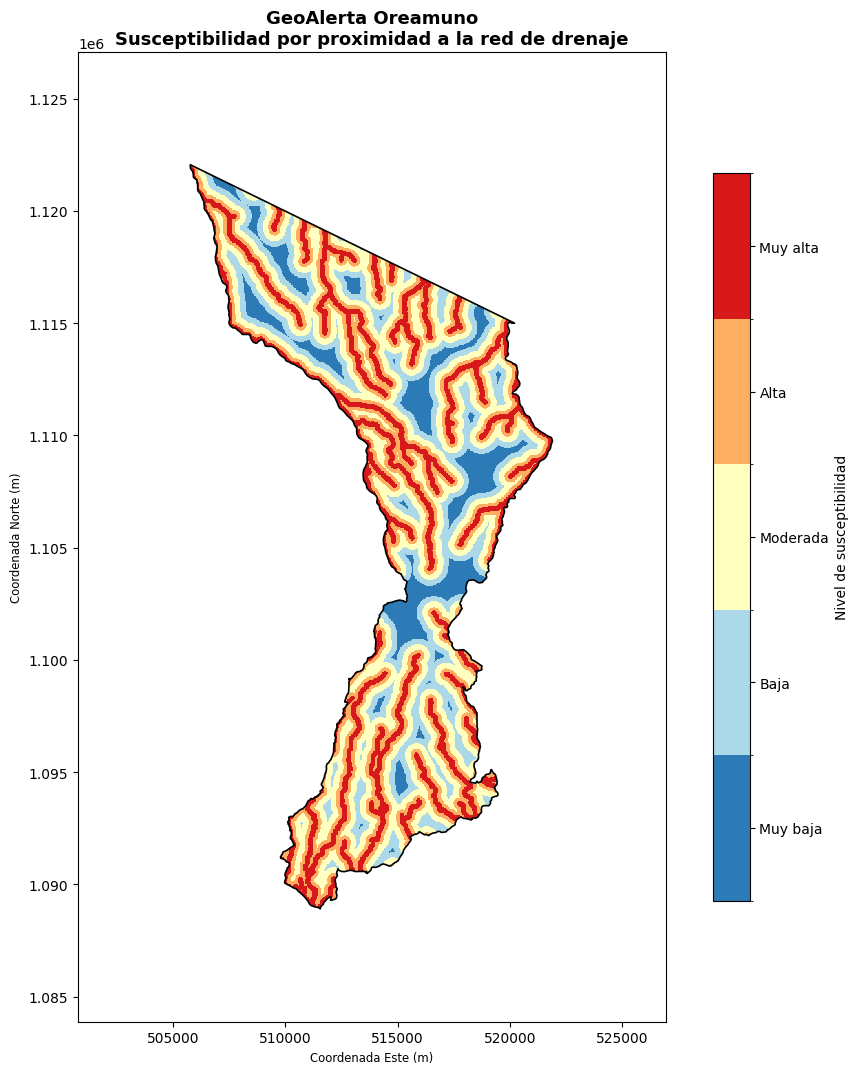

In [265]:
import rasterio
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from rasterio.plot import plotting_extent
from matplotlib.colors import ListedColormap, BoundaryNorm
from pathlib import Path

base = Path("/content/GeoAlerta_Oreamuno")

# Ráster clasificado
ruta_raster = (
    base / "03_Modelos_Hidrologicos/"
    "Oreamuno_Susceptibilidad_Proximidad_Drenaje.tif"
)

# Límite cantonal
ruta_canton = base / "01_Datos_Originales/Oreamuno_Canton.gpkg"

with rasterio.open(ruta_raster) as src:
    datos = src.read(1)
    datos = np.ma.masked_equal(datos, 0)
    extension = plotting_extent(src)

canton = gpd.read_file(ruta_canton)

# Colores para los cinco niveles
colores = [
    "#2C7BB6",  # Muy baja
    "#ABD9E9",  # Baja
    "#FFFFBF",  # Moderada
    "#FDAE61",  # Alta
    "#D7191C"   # Muy alta
]

nombres = [
    "Muy baja",
    "Baja",
    "Moderada",
    "Alta",
    "Muy alta"
]

cmap = ListedColormap(colores)
norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5, 4.5, 5.5],
    cmap.N
)

# Crear mapa
fig, ax = plt.subplots(figsize=(10, 11))

imagen = ax.imshow(
    datos,
    extent=extension,
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)

canton.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.2
)

barra = plt.colorbar(
    imagen,
    ax=ax,
    ticks=[1, 2, 3, 4, 5],
    shrink=0.75
)

barra.ax.set_yticklabels(nombres)
barra.set_label("Nivel de susceptibilidad")

ax.set_title(
    "GeoAlerta Oreamuno\nSusceptibilidad por proximidad a la red de drenaje",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Coordenada Este (m)")
ax.set_ylabel("Coordenada Norte (m)")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [270]:
from google.colab import output
output.enable_custom_widget_manager()

In [274]:
import rasterio
import numpy as np
from pathlib import Path

base = Path("/content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos")

entrada = base / "Oreamuno_Acumulacion_Flujo.tif"
salida = base / "Oreamuno_Susceptibilidad_Acumulacion_Flujo.tif"

with rasterio.open(entrada) as src:

    acumulacion = src.read(1)
    perfil = src.profile.copy()
    mascara = src.read_masks(1) > 0

    # Crear clasificación
    clasificado = np.zeros(acumulacion.shape, dtype="uint8")

    # Cinco niveles preliminares
    clasificado[mascara & (acumulacion < 10)] = 1
    clasificado[mascara & (acumulacion >= 10) & (acumulacion < 42)] = 2
    clasificado[mascara & (acumulacion >= 42) & (acumulacion < 188)] = 3
    clasificado[mascara & (acumulacion >= 188) & (acumulacion < 4123)] = 4
    clasificado[mascara & (acumulacion >= 4123)] = 5

    perfil.update(
        dtype="uint8",
        count=1,
        nodata=0,
        compress="lzw"
    )

    with rasterio.open(salida, "w", **perfil) as dst:
        dst.write(clasificado, 1)

    print("Ráster generado:", salida)

# Distribución
valores, conteos = np.unique(
    clasificado[mascara],
    return_counts=True
)

categorias = {
    1: "Muy baja",
    2: "Baja",
    3: "Moderada",
    4: "Alta",
    5: "Muy alta"
}

print("\nDISTRIBUCIÓN DE ACUMULACIÓN DE FLUJO")

for valor, cantidad in zip(valores, conteos):
    print(
        categorias[valor],
        "| Píxeles:", cantidad,
        "| Porcentaje:",
        round(cantidad / mascara.sum() * 100, 2), "%"
    )

Ráster generado: /content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Susceptibilidad_Acumulacion_Flujo.tif

DISTRIBUCIÓN DE ACUMULACIÓN DE FLUJO
Muy baja | Píxeles: 946194 | Porcentaje: 78.63 %
Baja | Píxeles: 138112 | Porcentaje: 11.48 %
Moderada | Píxeles: 56844 | Porcentaje: 4.72 %
Alta | Píxeles: 48267 | Porcentaje: 4.01 %
Muy alta | Píxeles: 13869 | Porcentaje: 1.15 %


In [275]:
import rasterio
import geopandas as gpd
import numpy as np
from rasterio.features import geometry_mask
from pathlib import Path

base = Path("/content/GeoAlerta_Oreamuno")
carpeta = base / "03_Modelos_Hidrologicos"

entrada = carpeta / "Oreamuno_Acumulacion_Flujo.tif"
salida = carpeta / "Oreamuno_Susceptibilidad_Acumulacion_Flujo.tif"
archivo_canton = base / "01_Datos_Originales/Oreamuno_Canton.gpkg"

# Se carga el límite cantonal
canton = gpd.read_file(archivo_canton)

with rasterio.open(entrada) as src:

    acumulacion = src.read(1)
    perfil = src.profile.copy()

    # Se adapta el límite cantonal al sistema de coordenadas del ráster
    canton = canton.to_crs(src.crs)

    # Se crea una máscara espacial del cantón
    mascara_canton = geometry_mask(
        canton.geometry,
        out_shape=acumulacion.shape,
        transform=src.transform,
        invert=True
    )

    # Se consideran únicamente píxeles válidos dentro del cantón
    mascara = (src.read_masks(1) > 0) & mascara_canton

    # Clasificación de acumulación de flujo
    clasificado = np.zeros(acumulacion.shape, dtype="uint8")

    clasificado[mascara & (acumulacion < 10)] = 1
    clasificado[mascara & (acumulacion >= 10) & (acumulacion < 42)] = 2
    clasificado[mascara & (acumulacion >= 42) & (acumulacion < 188)] = 3
    clasificado[mascara & (acumulacion >= 188) & (acumulacion < 4123)] = 4
    clasificado[mascara & (acumulacion >= 4123)] = 5

    perfil.update(
        dtype="uint8",
        count=1,
        nodata=0,
        compress="lzw"
    )

    with rasterio.open(salida, "w", **perfil) as dst:
        dst.write(clasificado, 1)

# Distribución dentro del cantón
categorias, conteos = np.unique(
    clasificado[mascara],
    return_counts=True
)

nombres = {
    1: "Muy baja",
    2: "Baja",
    3: "Moderada",
    4: "Alta",
    5: "Muy alta"
}

total = conteos.sum()

print("DISTRIBUCIÓN DE ACUMULACIÓN DE FLUJO - OREAMUNO")
print(f"Total de píxeles: {total:,}")

for categoria, cantidad in zip(categorias, conteos):
    porcentaje = cantidad / total * 100
    print(
        f"{nombres[categoria]} | "
        f"Píxeles: {cantidad:,} | "
        f"Porcentaje: {porcentaje:.2f} %"
    )

print("\nRáster guardado:", salida)

DISTRIBUCIÓN DE ACUMULACIÓN DE FLUJO - OREAMUNO
Total de píxeles: 215,992
Muy baja | Píxeles: 165,827 | Porcentaje: 76.77 %
Baja | Píxeles: 28,490 | Porcentaje: 13.19 %
Moderada | Píxeles: 10,865 | Porcentaje: 5.03 %
Alta | Píxeles: 8,648 | Porcentaje: 4.00 %
Muy alta | Píxeles: 2,162 | Porcentaje: 1.00 %

Ráster guardado: /content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Susceptibilidad_Acumulacion_Flujo.tif


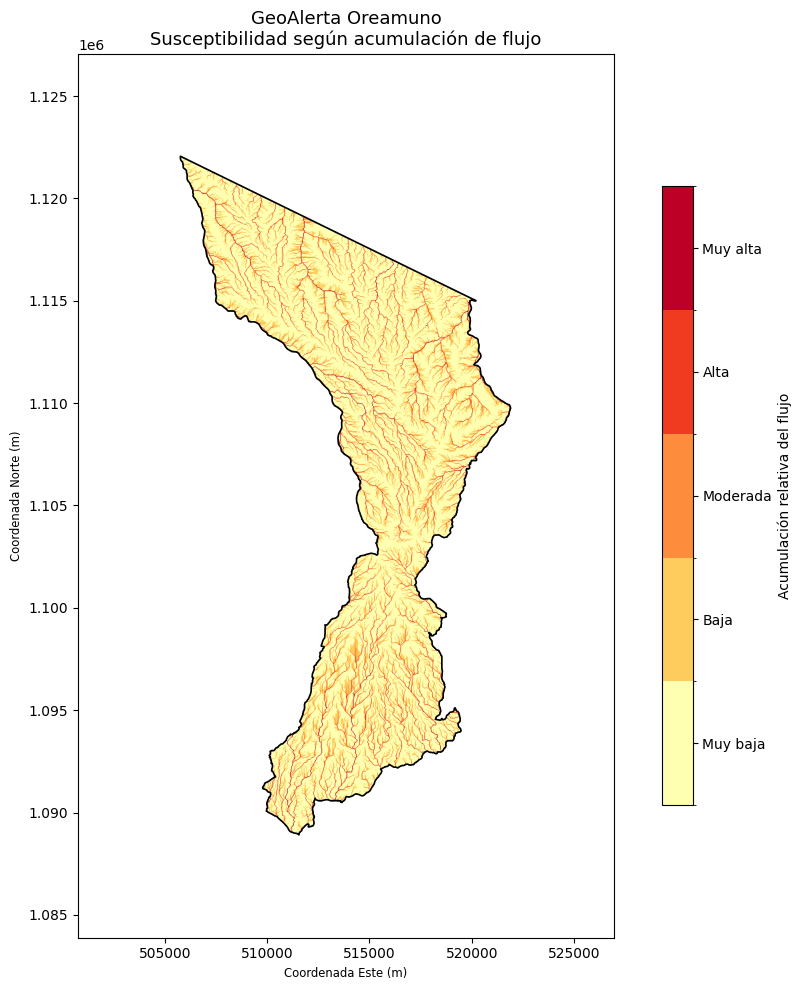

In [276]:
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from rasterio.plot import plotting_extent
from matplotlib.colors import ListedColormap, BoundaryNorm
from pathlib import Path

base = Path("/content/GeoAlerta_Oreamuno")
carpeta = base / "03_Modelos_Hidrologicos"

archivo = carpeta / "Oreamuno_Susceptibilidad_Acumulacion_Flujo.tif"
canton = gpd.read_file(
    base / "01_Datos_Originales/Oreamuno_Canton.gpkg"
)

with rasterio.open(archivo) as src:
    datos = src.read(1).astype(float)
    datos[datos == 0] = np.nan
    extension = plotting_extent(src)
    canton = canton.to_crs(src.crs)

colores = ["#ffffb2", "#fecc5c", "#fd8d3c", "#f03b20", "#bd0026"]
cmap = ListedColormap(colores)
norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5, 5.5], cmap.N)

fig, ax = plt.subplots(figsize=(10, 10))

imagen = ax.imshow(
    datos,
    extent=extension,
    cmap=cmap,
    norm=norm
)

canton.boundary.plot(ax=ax, color="black", linewidth=1.2)

barra = plt.colorbar(imagen, ax=ax, ticks=[1, 2, 3, 4, 5], shrink=0.7)
barra.ax.set_yticklabels([
    "Muy baja", "Baja", "Moderada", "Alta", "Muy alta"
])
barra.set_label("Acumulación relativa del flujo")

ax.set_title(
    "GeoAlerta Oreamuno\nSusceptibilidad según acumulación de flujo",
    fontsize=13
)
ax.set_xlabel("Coordenada Este (m)")
ax.set_ylabel("Coordenada Norte (m)")

plt.tight_layout()
plt.show()

In [279]:
import rasterio
import geopandas as gpd
import numpy as np
from rasterio.features import geometry_mask
from pathlib import Path

base = Path("/content/GeoAlerta_Oreamuno")
entrada = base / "02_Datos_Procesados/Oreamuno_Pendiente_grados.tif"
canton = gpd.read_file(
    base / "01_Datos_Originales/Oreamuno_Canton.gpkg"
)

with rasterio.open(entrada) as src:

    pendiente = src.read(1)
    canton = canton.to_crs(src.crs)

    mascara_canton = geometry_mask(
        canton.geometry,
        out_shape=pendiente.shape,
        transform=src.transform,
        invert=True
    )

    mascara = (src.read_masks(1) > 0) & mascara_canton
    valores = pendiente[mascara]

    print("DISTRIBUCIÓN DE PENDIENTES - OREAMUNO")
    print(f"Píxeles: {len(valores):,}")

    for p in [0, 10, 25, 50, 75, 90, 95, 99, 100]:
        print(f"P{p}: {np.percentile(valores, p):.2f}°")

DISTRIBUCIÓN DE PENDIENTES - OREAMUNO
Píxeles: 215,992
P0: 0.03°
P10: 5.26°
P25: 8.46°
P50: 14.12°
P75: 26.93°
P90: 39.64°
P95: 44.86°
P99: 54.01°
P100: 69.56°


In [280]:
import rasterio
import geopandas as gpd
import numpy as np
from rasterio.features import geometry_mask
from pathlib import Path

base = Path("/content/GeoAlerta_Oreamuno")
carpeta = base / "03_Modelos_Hidrologicos"

entrada = base / "02_Datos_Procesados/Oreamuno_Pendiente_grados.tif"
salida = carpeta / "Oreamuno_Susceptibilidad_Pendiente.tif"

canton = gpd.read_file(
    base / "01_Datos_Originales/Oreamuno_Canton.gpkg"
)

with rasterio.open(entrada) as src:

    pendiente = src.read(1)
    perfil = src.profile.copy()

    canton = canton.to_crs(src.crs)

    mascara_canton = geometry_mask(
        canton.geometry,
        out_shape=pendiente.shape,
        transform=src.transform,
        invert=True
    )

    mascara = (src.read_masks(1) > 0) & mascara_canton

    clasificado = np.zeros(pendiente.shape, dtype="uint8")

    clasificado[mascara & (pendiente <= 5)] = 5
    clasificado[mascara & (pendiente > 5) & (pendiente <= 10)] = 4
    clasificado[mascara & (pendiente > 10) & (pendiente <= 20)] = 3
    clasificado[mascara & (pendiente > 20) & (pendiente <= 35)] = 2
    clasificado[mascara & (pendiente > 35)] = 1

    perfil.update(
        dtype="uint8",
        count=1,
        nodata=0,
        compress="lzw"
    )

    with rasterio.open(salida, "w", **perfil) as dst:
        dst.write(clasificado, 1)

categorias, conteos = np.unique(
    clasificado[mascara],
    return_counts=True
)

nombres = {
    1: "Muy baja",
    2: "Baja",
    3: "Moderada",
    4: "Alta",
    5: "Muy alta"
}

total = conteos.sum()

print("DISTRIBUCIÓN DE SUSCEPTIBILIDAD POR PENDIENTE")
print(f"Total de píxeles: {total:,}")

for categoria, cantidad in zip(categorias, conteos):
    print(
        f"{nombres[categoria]} | "
        f"Píxeles: {cantidad:,} | "
        f"Porcentaje: {cantidad / total * 100:.2f} %"
    )

print("\nRáster guardado:", salida)

DISTRIBUCIÓN DE SUSCEPTIBILIDAD POR PENDIENTE
Total de píxeles: 215,992
Muy baja | Píxeles: 33,615 | Porcentaje: 15.56 %
Baja | Píxeles: 42,270 | Porcentaje: 19.57 %
Moderada | Píxeles: 69,056 | Porcentaje: 31.97 %
Alta | Píxeles: 51,509 | Porcentaje: 23.85 %
Muy alta | Píxeles: 19,542 | Porcentaje: 9.05 %

Ráster guardado: /content/GeoAlerta_Oreamuno/03_Modelos_Hidrologicos/Oreamuno_Susceptibilidad_Pendiente.tif


In [289]:

!pip install -q osmnx geopandas pyogrio

import osmnx as ox
import geopandas as gpd
import pandas as pd
import numpy as np
from pathlib import Path

print("Librerías cargadas correctamente.")
print("OSMnx:", ox.__version__)


Librerías cargadas correctamente.
OSMnx: 2.1.2


In [291]:
import os
import requests
import geopandas as gpd
from pathlib import Path

base = Path("/content/GeoAlerta_Oreamuno")
ruta_limite = base / "01_Datos_Originales" / "Oreamuno_Canton.gpkg"

# Crear directorios necesarios
base.mkdir(parents=True, exist_ok=True)
(base / "01_Datos_Originales").mkdir(parents=True, exist_ok=True)

carpeta_exposicion = base / "02_Exposicion_Territorial"
carpeta_exposicion.mkdir(parents=True, exist_ok=True)

# Mecanismo de auto-recuperación si el archivo fue borrado por reinicio de sesión
if not ruta_limite.exists():
    print("⚐ El archivo local 'Oreamuno_Canton.gpkg' no existe.")
    print("Descargando y regenerando el límite cantonal desde el servidor cartográfico...")

    URL_CANTONES = (
        "https://services5.arcgis.com/4u1m1BBDkNDTVWsd/"
        "arcgis/rest/services/Cant%C3%B3n/FeatureServer/0/query"
    )

    parametros = {
        "where": "1=1",
        "outFields": "*",
        "returnGeometry": "true",
        "outSR": "5367",
        "f": "geojson"
    }

    respuesta = requests.get(URL_CANTONES, params=parametros, timeout=120)
    respuesta.raise_for_status()

    cantones = gpd.GeoDataFrame.from_features(
        respuesta.json()["features"],
        crs="EPSG:5367"
    )

    # Filtrar el cantón de Oreamuno y guardarlo
    oreamuno_temp = cantones[cantones["nom_cant"].str.upper() == "OREAMUNO"].copy()
    oreamuno_temp.to_file(ruta_limite, driver="GPKG")
    print("✅ Límite cantonal regenerado y guardado con éxito.")

# Leer límite cantonal
limite = gpd.read_file(ruta_limite)

# Unificar geometrías
limite = limite.dissolve()

# Preparar geometría para consulta OSM
limite_4326 = limite.to_crs("EPSG:4326")
poligono = limite_4326.geometry.iloc[0]

print("\nLÍMITE TERRITORIAL")
print("CRS:", limite.crs)
print("Área:", round(limite.to_crs(5367).area.sum()/1e6, 2), "km")
print("Geometría:", poligono.geom_type)
print("Archivo:", ruta_limite)


LÍMITE TERRITORIAL
CRS: EPSG:5367
Área: 202.9 km
Geometría: Polygon
Archivo: /content/GeoAlerta_Oreamuno/01_Datos_Originales/Oreamuno_Canton.gpkg


In [292]:

ox.settings.use_cache = True
ox.settings.timeout = 180

consultas = {
    "Edificaciones": {"building": True},

    "Red_Vial": {"highway": True},

    "Infraestructura": {
        "amenity": [
            "school",
            "kindergarten",
            "college",
            "university",
            "hospital",
            "clinic",
            "doctors",
            "police"
        ],
        "emergency": [
            "fire_station",
            "ambulance_station"
        ]
    }
}

capas_osm = {}

for nombre, etiquetas in consultas.items():

    print(f"\nDescargando: {nombre}")

    try:
        datos = ox.features_from_polygon(
            poligono,
            tags=etiquetas
        )

        if datos.empty:
            print("No se encontraron elementos.")
            continue

        datos = datos.reset_index(drop=True)

        # Recortar al límite cantonal
        datos = gpd.clip(datos, limite_4326)

        # Proyectar a CRTM05
        datos = datos.to_crs("EPSG:5367")

        # Guardar
        salida = carpeta_exposicion / f"Oreamuno_{nombre}.gpkg"

        datos.to_file(
            salida,
            driver="GPKG",
            layer=nombre
        )

        capas_osm[nombre] = datos

        print(f"Elementos: {len(datos):,}")
        print(f"Guardado: {salida}")

    except Exception as e:
        print(f"Error en {nombre}: {e}")

print("\nDESCARGA FINALIZADA")



Descargando: Edificaciones
Elementos: 1,338
Guardado: /content/GeoAlerta_Oreamuno/02_Exposicion_Territorial/Oreamuno_Edificaciones.gpkg

Descargando: Red_Vial
Elementos: 1,119
Guardado: /content/GeoAlerta_Oreamuno/02_Exposicion_Territorial/Oreamuno_Red_Vial.gpkg

Descargando: Infraestructura
Error en Infraestructura: 'overpass-api.de' responded: 413 Request Entity Too Large <html>
<head><title>413 Request Entity Too Large</title></head>
<body>
<center><h1>413 Request Entity Too Large</h1></center>
<hr><center>nginx</center>
</body>
</html>


DESCARGA FINALIZADA


In [293]:
# Asegurar la instalación de pysheds en el entorno actual
!pip install -q pysheds

import geopandas as gpd
import ee
import requests
import rasterio
import numpy as np
import os
from pathlib import Path
from rasterio.io import MemoryFile
from rasterio.warp import reproject, Resampling
from pysheds.grid import Grid

# 0. Inicializar Google Earth Engine de forma segura
try:
    ee.Initialize(project="future-campaign-276316")
except Exception:
    from google.colab import auth
    auth.authenticate_user()
    ee.Authenticate(auth_mode='colab')
    ee.Initialize(project="future-campaign-276316")

base = Path("/content/GeoAlerta_Oreamuno")
carpeta = base / "02_Exposicion_Territorial"
carpeta.mkdir(parents=True, exist_ok=True)

# 1. Asegurar la existencia de las dependencias e insumos espaciales (Auto-recuperación)
ruta_dem_original = base / "01_Datos_Originales/Oreamuno_Copernicus_GLO30.tif"
ruta_dem_proyectado = base / "02_Datos_Procesados/Oreamuno_Copernicus_GLO30_CRTM05.tif"
ruta_dem = base / "03_Modelos_Hidrologicos/Oreamuno_DEM_Acondicionado.tif"

# Si el DEM acondicionado no existe, lo regeneramos desde Copernicus
if not ruta_dem.exists():
    print("⚠️ DEM Acondicionado no encontrado. Regenerando insumos de elevación...")
    os.makedirs(ruta_dem.parent, exist_ok=True)
    os.makedirs(ruta_dem_proyectado.parent, exist_ok=True)
    os.makedirs(ruta_dem_original.parent, exist_ok=True)

    # Descargar Copernicus DEM si no existe
    if not ruta_dem_original.exists():
        import math
        from rasterio.merge import merge
        from rasterio.warp import transform_bounds

        # Recrear extensión
        limite_temp = gpd.read_file(base / "01_Datos_Originales/Oreamuno_Canton.gpkg")
        geometria_union = limite_temp.geometry.union_all()
        area_descarga = geometria_union.buffer(5000)
        xmin, ymin, xmax, ymax = area_descarga.bounds
        lon_min, lat_min, lon_max, lat_max = transform_bounds("EPSG:5367", "EPSG:4326", xmin, ymin, xmax, ymax, densify_pts=21)

        def _url_tesela(lat, lon, glo=30):
            res = "10" if glo == 30 else "30"
            ns = "N" if lat >= 0 else "S"
            ew = "E" if lon >= 0 else "W"
            nombre = f"Copernicus_DSM_COG_{res}_{ns}{abs(lat):02d}_00_{ew}{abs(lon):03d}_00_DEM"
            return f"https://copernicus-dem-{glo}m.s3.amazonaws.com/{nombre}/{nombre}.tif"

        teselas = [(la, lo) for la in range(math.floor(lat_min), math.floor(lat_max) + 1) for lo in range(math.floor(lon_min), math.floor(lon_max) + 1)]
        abiertas = [rasterio.open(_url_tesela(la, lo, 30)) for la, lo in teselas]
        mosaico, transform = merge(abiertas, bounds=(lon_min, lat_min, lon_max, lat_max))
        perfil = abiertas[0].profile.copy()
        perfil.update(driver="GTiff", count=1, height=mosaico.shape[1], width=mosaico.shape[2], transform=transform)
        with rasterio.open(ruta_dem_original, "w", **perfil) as dst:
            dst.write(mosaico[0], 1)
        for a in abiertas: a.close()

    # Reproyectar a CRTM05 si no existe
    if not ruta_dem_proyectado.exists():
        from rasterio.warp import calculate_default_transform
        with rasterio.open(ruta_dem_original) as src:
            transformacion, ancho, alto = calculate_default_transform(src.crs, "EPSG:5367", src.width, src.height, *src.bounds)
            nodata = src.nodata if src.nodata is not None else -9999.0
            destino = np.full((alto, ancho), nodata, dtype=np.float32)
            reproject(source=rasterio.band(src, 1), destination=destino, src_transform=src.transform, src_crs=src.crs, src_nodata=src.nodata, dst_transform=transformacion, dst_crs="EPSG:5367", dst_nodata=nodata, resampling=Resampling.bilinear)
            perfil_salida = src.profile.copy()
            perfil_salida.update(driver="GTiff", crs="EPSG:5367", transform=transformacion, width=ancho, height=alto, count=1, dtype="float32", nodata=nodata, compress="deflate")
        with rasterio.open(ruta_dem_proyectado, "w", **perfil_salida) as dst:
            dst.write(destino, 1)

    # Acondicionamiento hidrológico (convertido a str para compatibilidad con PySheds)
    grid = Grid.from_raster(str(ruta_dem_proyectado))
    dem_pysheds = grid.read_raster(str(ruta_dem_proyectado))
    dem_sin_pozos = grid.fill_pits(dem_pysheds)
    dem_relleno = grid.fill_depressions(dem_sin_pozos)
    dem_acondicionado = grid.resolve_flats(dem_relleno)
    with rasterio.open(ruta_dem_proyectado) as src:
        perfil_hidrologico = src.profile.copy()
    perfil_hidrologico.update(dtype="float32", count=1, compress="deflate")
    with rasterio.open(ruta_dem, "w", **perfil_hidrologico) as dst:
        dst.write(np.asarray(dem_acondicionado, dtype="float32"), 1)
    print("✅ DEM Acondicionado regenerado con éxito.")

# 2. Cargar el límite cantonal en WGS84 para Earth Engine
ruta_limite = base / "01_Datos_Originales/Oreamuno_Canton.gpkg"
limite = gpd.read_file(ruta_limite)
limite_wgs84 = limite.to_crs("EPSG:4326")

geometria_union = limite_wgs84.geometry.union_all()
region_ee = ee.Geometry(geometria_union.__geo_interface__)

# 3. Consultar y descargar población desde WorldPop (Año 2020)
print("Consultando población en WorldPop (Earth Engine)...")
pop_col = ee.ImageCollection("WorldPop/GP/100m/pop") \
    .filterBounds(region_ee) \
    .filter(ee.Filter.eq("year", 2020)) \
    .filter(ee.Filter.eq("country", "CRI"))

pop_image = pop_col.first().select("population").clip(region_ee)

url_descarga = pop_image.getDownloadURL({
    'scale': 100,
    'crs': 'EPSG:4326',
    'region': region_ee,
    'format': 'GEO_TIFF'
})

print("Descargando ráster de población...")
respuesta = requests.get(url_descarga)
respuesta.raise_for_status()

# 4. Leer la referencia espacial del DEM para alinear el resultado
with rasterio.open(ruta_dem) as dem_ref:
    perfil_dem = dem_ref.profile.copy()
    alto = dem_ref.height
    ancho = dem_ref.width
    transform_dem = dem_ref.transform
    crs_dem = dem_ref.crs

# 5. Reproyectar y alinear la población al DEM en CRTM05
poblacion_alineada = np.zeros((alto, ancho), dtype=np.float32)

with MemoryFile(respuesta.content) as memfile:
    with memfile.open() as src_pop:
        reproject(
            source=rasterio.band(src_pop, 1),
            destination=poblacion_alineada,
            src_transform=src_pop.transform,
            src_crs=src_pop.crs,
            src_nodata=src_pop.nodata,
            dst_transform=transform_dem,
            dst_crs=crs_dem,
            dst_nodata=-9999,
            resampling=Resampling.bilinear
        )

# Reemplazar valores negativos residuales con 0
poblacion_alineada[poblacion_alineada < 0] = 0

# 6. Guardar el archivo recortado y proyectado
ruta_recorte = carpeta / "Oreamuno_Poblacion_Recortada.tif"
perfil_dem.update(
    dtype="float32",
    count=1,
    nodata=0,
    compress="lzw"
)

with rasterio.open(ruta_recorte, "w", **perfil_dem) as dst:
    dst.write(poblacion_alineada, 1)

print("\nPoblación obtenida y recortada correctamente.")
print("Suma de población estimada (WorldPop):", round(float(np.nansum(poblacion_alineada))))
print("Archivo guardado en:", ruta_recorte)

Consultando población en WorldPop (Earth Engine)...
Descargando ráster de población...

Población obtenida y recortada correctamente.
Suma de población estimada (WorldPop): 1625460
Archivo guardado en: /content/GeoAlerta_Oreamuno/02_Exposicion_Territorial/Oreamuno_Poblacion_Recortada.tif


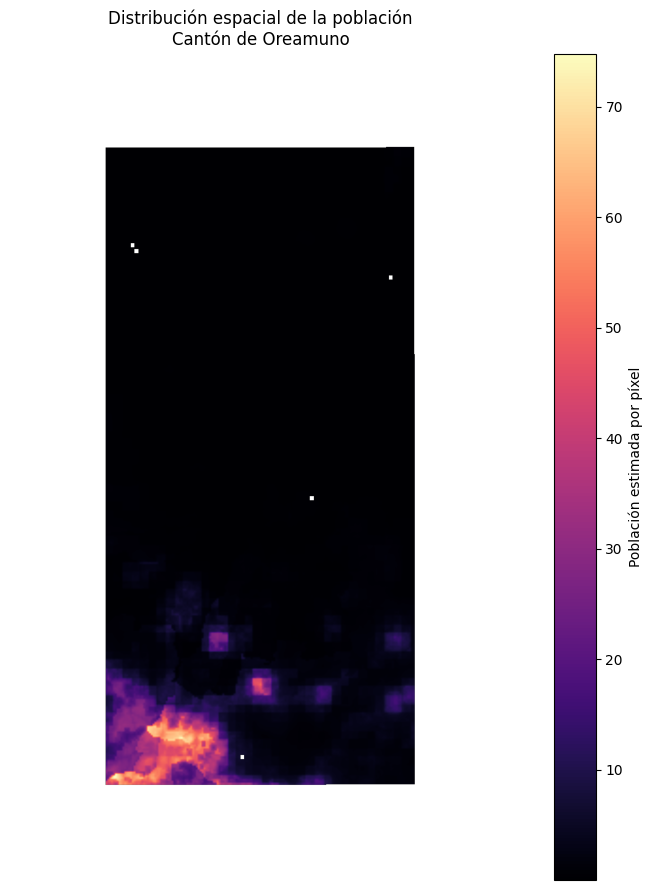

In [294]:
import matplotlib.pyplot as plt
import numpy as np

# Corregido: Se utiliza la variable correcta 'poblacion_alineada' definida en la celda anterior
datos = poblacion_alineada.astype(float)
datos[datos <= 0] = np.nan

fig, ax = plt.subplots(figsize=(9, 9))

im = ax.imshow(
    datos,
    cmap="magma"
)

plt.colorbar(
    im,
    ax=ax,
    label="Población estimada por píxel"
)

ax.set_title(
    "Distribución espacial de la población\nCantón de Oreamuno"
)

ax.axis(
    "off"
)
plt.tight_layout()
plt.show()